# What should adaptive therapy optimise? Follow-up experiments

This notebook runs the follow-up experiments proposed in `further expts.txt` (project root). It **does not modify** `experiments.ipynb` or its results. It reloads that notebook's cached agents, re-derives its baselines and value-iteration (VI) ceilings, checks that they reproduce the published numbers, and adds the new experiments alongside.

| File (this folder) | What it holds |
|---|---|
| `relevance.md` | every proposed experiment, judged against the original Phase 2 plan: does it **defend** an existing claim, give a **new insight** for the paper, or neither; and what was done |
| `decisions.md` | every design choice made here (numbered F1, F2, ..., continuing the root `decisions.md`) |
| `model_flow.md` | what changed in the model and MDP, and how data flows from the ODE to each new result |
| `fx.py` | the extra patients, every PPO job, and the switching-penalty VI. `python fx.py` trains everything (cached) |
| `results/`, `figures/` | outputs of this notebook only |

**Rules carried over from Phase 2** (doc, "How to read"):
1. Change one thing at a time.
2. Same algorithm, architecture, step budget and seeds for every objective; no per-objective tuning.
3. Whenever the environment or the action set changes, re-solve VI and score against the **matching** ceiling.
4. Ten seeds per objective, seed spread is the noise floor, agents below 0.7 of their own ceiling *did not train*.
5. A changed ODE or action set is a separate experiment; the old results stay as its baseline.

**Tags.** [ANALYSIS] no retraining · [REWARD] reward code only · [CONFIG] same model, other patient/budget/grid · [ENV] model or action set changed · **VI-only** = answered with value iteration alone, no PPO.

| § | Item | Tag | Why it matters for the paper | Done here |
|---|---|---|---|---|
| 1 | B1 Pareto frontier | ANALYSIS | new: is the highest-reward policy a good dose/TTP trade-off? | yes |
| 2 | B2 R3 reward shape | REWARD | defends "R3 last" against "it is your reward maths" | PPO + VI |
| 3 | A3 finer VI grid | CONFIG | defends every score (all are fractions of the ceilings) | yes |
| 3 | A1 turnover > 0 patient | CONFIG | closes the README limitation "both reference patients have turnover 0" | PPO |
| 3 | A2 3× budget for all settings | CONFIG | closes the D43 budget confound; tests "burden-only beats full state" | PPO |
| 4 | C1 cost × turnover map | CONFIG | turns "two patients" into "this region"; the Phase 2 plan's Gallagher-5c map | VI-only |
| 5 | B3 switch counts | ANALYSIS | gates D4; a clinical-practicality number | yes |
| 5 | D1 three doses | ENV | new: graded doses were excluded by root D8; tests R1 ≡ R4 | PPO + VI |
| 5 | D2 2 / 3 / 5 levels | ENV | new: planner flexibility vs PPO learnability | PPO + VI |
| 5 | D3 dose-response shape | ENV | qualifies D1/D2 | VI-only |
| 5 | D4 switching penalty | REWARD + state | new: can the schedule be simplified? | VI-only |
| 6 | E1 S → R conversion | ENV | new: the README's named route to durability ≠ survival | PPO + VI |
| 6 | E2 partly sensitive R | ENV | defends finding 4 (why coexistence fails) | VI-only |
| 7 | B4 progression threshold | ENV-lite | sensitivity of the whole control problem | VI-only |
| 8 | A4, A5, E3, E4, Part F | | see §8 and `relevance.md` | not done |

Run order: `python fx.py 4` (≈ 5 h on 4 workers, resumable: each finished job is cached), then execute this notebook (≈ 25 min, it never trains).

In [1]:
import os, sys, json, itertools
from types import SimpleNamespace
sys.path.insert(0, os.path.abspath('.'))          # fx.py, which itself puts ../src (atrl) on the path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from fx import *   # atrl (model, objectives, VI, PPO) + this folder's patients, jobs and switching-penalty VI

RES, FIG, ORIG = 'results', 'figures', '../results'   # this notebook's outputs | the original experiments
os.makedirs(RES, exist_ok=True); os.makedirs(FIG, exist_ok=True)
with open(f'{ORIG}/summary.json') as f:
    ORIG_SUMMARY = json.load(f)
SUMMARY = {}

# style and helpers below are copied from experiments.ipynb, so every number is computed the same way (root D38)
COL = dict(R1='#2a78d6', R2='#eb6834', R3='#1baf7a', R4='#eda100')
INK, MUTED, GRID, NAVY = '#2A2A2A', '#898781', '#E1E0D9', '#1B2A4A'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
BLUES.set_bad('#EDEDEA')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': GRID, 'grid.linewidth': .8, 'axes.edgecolor': '#C3C2B7',
                     'axes.axisbelow': True, 'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'font.size': 10, 'lines.linewidth': 2, 'figure.dpi': 100,
                     'legend.frameon': False})
pd.set_option('display.precision', 3, 'display.width', 220, 'display.max_columns', 40)
ALPHA = .05 / 6
COLS = ['TTP', 'dose', 'dose_pct', 'mean_fR', 'term_fR', 'mean_burden', 'regrow', 'f_holiday', 'G_R1', 'G_R2', 'G_R3', 'G_R4']


def save(name):
    plt.savefig(f'{FIG}/{name}.png', dpi=160, bbox_inches='tight'); plt.show()


def miqr(x):
    # median [IQR]: medians and spread, never the mean alone (Phase 2, Metrics)
    q = np.nanpercentile(np.asarray(x, float), [25, 50, 75])
    return f'{q[1]:.3g} [{q[0]:.3g}, {q[2]:.3g}]'


def evaluate(pols, patients=(POP,), interval=7, drug='cytotoxic', objs=OBJECTIVES):
    # score {name: policy} on every metric for every patient -> long DataFrame
    rows = []
    for name, pol in pols.items():
        m = rollout(pol, list(patients), interval=interval, drug=drug, objs=objs)
        keys = [k for k in m if k not in ('traj', 'progressed')]
        rows += [dict(policy=name, patient=i, **{k: m[k][i] for k in keys}) for i in range(len(patients))]
    return pd.DataFrame(rows)


def split(df):
    # 'R1|s3' -> obj='R1', seed='s3'
    df = df.copy()
    df['obj'], df['seed'] = df.policy.str.split('|').str[0], df.policy.str.split('|').str[1]
    return df


def score(G, obj, floor, ceil):
    # discounted return rescaled so no treatment = 0 and the VI optimum = 1 (nan if the optimum is no better than no treatment)
    span = ceil[obj] - floor[obj]
    return (G - floor[obj]) / span if span > 0.05 else G * np.nan

In [2]:
# ---- E4/E5 analysis of experiments.ipynb (verbatim), with policy_space generalised to graded doses ----
def score_matrix(ok, e1, e2, floor, ceil, extra):
    rows = list(OBJECTIVES) + [f'VI-{o}' for o in OBJECTIVES] + extra
    M = pd.DataFrame(index=rows, columns=OBJECTIVES, dtype=float)
    for o in OBJECTIVES:
        for o2 in OBJECTIVES:
            M.loc[o, o2] = np.median(score(ok[ok.obj == o][f'G_{o2}'], o2, floor, ceil))
    for k in rows[4:]:
        src = e2 if k.startswith('VI') else e1
        for o2 in OBJECTIVES:
            M.loc[k, o2] = score(src.loc[k, f'G_{o2}'], o2, floor, ceil)
    loss = pd.DataFrame({o2: {o: M.loc[o2, o2] - M.loc[o, o2] for o in OBJECTIVES} for o2 in OBJECTIVES})
    return M, loss


def plot_score_matrix(ax, M, title):
    ax.imshow(M.values.clip(0, 1.05), cmap=BLUES, vmin=0, vmax=1.05, aspect='auto')
    for i in range(len(M)):
        for j in range(4):
            v = M.values[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9, color='white' if v > .6 else INK,
                    weight='bold' if i < 4 and i == j else 'normal')
    ax.set_xticks(range(4), [f'scored on {o}' for o in OBJECTIVES]); ax.set_yticks(range(len(M)), M.index)
    ax.axhline(3.5, color='white', lw=3); ax.axhline(7.5, color='white', lw=3); ax.grid(False)
    ax.set_title(title)


def ttp_tests(ok):
    have = [o for o in OBJECTIVES if (ok.obj == o).sum() >= 2]   # objectives with enough trained seeds
    kw = stats.kruskal(*[ok[ok.obj == o].TTP for o in have])
    pairs = []
    for a, b in itertools.combinations(have, 2):
        x, y = ok[ok.obj == a].TTP, ok[ok.obj == b].TTP
        pairs.append(dict(pair=f'{a} vs {b}', median_a=x.median(), median_b=y.median(),
                          diff=x.median() - y.median(), mannwhitney_p=stats.mannwhitneyu(x, y).pvalue))
    ic = (stats.mannwhitneyu(ok[ok.obj == 'R3'].TTP, ok[ok.obj == 'R1'].TTP, alternative='greater')
          if {'R1', 'R3'} <= set(have) else SimpleNamespace(pvalue=np.nan))
    print(f'Kruskal-Wallis on TTP across objectives: H = {kw.statistic:.2f}, p = {kw.pvalue:.2g}')
    print(f'Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = {ic.pvalue:.3g}',
          '-> HOLDS' if ic.pvalue < .05 else '-> does not hold')
    return kw, pd.DataFrame(pairs).set_index('pair'), ic


def plot_ttp(ax, ev, e1, e2, best_h, title):
    for i, o in enumerate(OBJECTIVES):
        d = ev[ev.obj == o]; jit = np.linspace(-.16, .16, len(d)); good = (d.own_score >= .7).values
        ax.scatter((i + jit)[good], d.TTP[good], s=40, color=COL[o], edgecolor='white', lw=1.2, zorder=3)
        ax.scatter((i + jit)[~good], d.TTP[~good], s=40, facecolor='none', edgecolor=COL[o], lw=1.4, zorder=3)
        if good.any():
            ax.plot([i - .25, i + .25], [d.TTP[good].median()] * 2, color=INK, lw=2, zorder=4)
    for name, v in (('VI-R1 optimum', e2.loc['VI-R1', 'TTP']), (best_h, e1.loc[best_h, 'TTP']),
                    ('AT50', e1.loc['AT50', 'TTP']), ('MTD', e1.loc['MTD', 'TTP'])):
        ax.axhline(v, color=MUTED, ls=(0, (4, 3)), lw=1); ax.text(3.45, v, name, color=MUTED, va='center', fontsize=8)
    ax.set_xticks(range(4), ['R1 survival+holiday', 'R2 dose+time', 'R3 coexistence', 'R4 durability'])
    ax.set_xlim(-.5, 4.1); ax.set_ylabel('TTP (days)'); ax.set_title(title)


def boot_ci(x, n=5000, rng=np.random.default_rng(0)):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if not len(x):
        return np.array([np.nan, np.nan])
    return np.round(np.percentile(np.median(rng.choice(x, (n, len(x))), 1), [2.5, 97.5]), 3)


def perm_test(D, lab, a, b, n_perm=5000):
    # between-objective divergence minus within-objective (seed-to-seed) divergence, label-permutation null
    rng = np.random.default_rng(0)
    idx = np.where((lab == a) | (lab == b))[0]; L = lab[idx]; sub = D[np.ix_(idx, idx)]; iu = np.triu_indices(len(idx), 1)
    def stat(L):
        same = (L[:, None] == L[None, :])[iu]; return sub[iu][~same].mean() - sub[iu][same].mean(), sub[iu][same].mean()
    t0, within = stat(L)
    null = np.array([stat(rng.permutation(L))[0] for _ in range(n_perm)])
    return t0 + within, within, (np.sum(null >= t0) + 1) / (n_perm + 1)


def dose_dist(pol, S, R, pB, acts):
    # (n, k) probability of each dose in acts: binary agents [1 - p, p], graded agents their categorical, VI one-hot
    if isinstance(pol, Agent):
        if pol.actions:
            return pol.dist(S, R, pB)
        p = pol.probs(S, R, pB)
        return np.c_[1 - p, p]
    return (np.asarray(acts)[None, :] == pol(S, R, 0.0, pB)[:, None]).astype(float)


def cat_kl(P, Q, eps=1e-6):
    # mean symmetric KL between dose distributions over a shared state set; equals atrl.sym_kl for two doses
    P, Q = np.clip(P, eps, 1 - eps), np.clip(Q, eps, 1 - eps)
    return float(0.5 * ((P * np.log(P / Q)).sum(-1) + (Q * np.log(Q / P)).sum(-1)).mean())


_p, _q = np.random.default_rng(0).random((2, 50))
assert np.isclose(cat_kl(np.c_[1 - _p, _p], np.c_[1 - _q, _q]), sym_kl(_p, _q))   # generalisation is exact for binary


def policy_space(p, agents, vip, base, ok, pairs=None, acts=(0.0, 1.0)):
    # experiments.ipynb E5 on a shared state set; KL over dose distributions, disagreement on the most likely dose,
    # threshold N* fitted to P(D > 0). For binary policies every number equals the original.
    pB, states = stack(p), []
    for pol in list(agents.values()) + list(vip.values()) + list(base.values()):
        tr = rollout(pol, [p], record=True, objs=())['traj']
        states.append(np.c_[tr['S'][:, 0], tr['R'][:, 0]])
    X = np.unique(np.round(np.concatenate(states), 5), axis=0)
    Sx, Rx = X[:, 0], X[:, 1]; nb = (Sx + Rx) / p['N0']
    P = {k: dose_dist(a, Sx, Rx, pB, acts) for k, a in (agents | vip).items()}
    print(f'shared state set: {len(X)} states, N/N0 in [{nb.min():.2f}, {nb.max():.2f}]')
    thr = pd.DataFrame([dict(policy=k, **dict(zip(('N_star', 'slope', 'R2'), fit_threshold(nb, 1 - P[k][:, 0])))) for k in P])
    thr_ag = split(thr[thr.policy.isin(ok.policy)])
    tab = thr_ag.groupby('obj').agg(N_star=('N_star', 'median'), slope=('slope', 'median'), R2_burden_only=('R2', 'median'))
    tab['N_star_95CI'] = [boot_ci(thr_ag[thr_ag.obj == o].N_star) for o in tab.index]
    tab = pd.concat([tab, thr[thr.policy.str.startswith('VI')].set_index('policy')[['N_star', 'slope', 'R2']]
                     .rename(columns={'R2': 'R2_burden_only'})])
    keys = list(ok.policy); lab = np.array([k.split('|')[0] for k in keys]); Pm = [P[k] for k in keys]
    n = len(keys); KL = np.zeros((n, n)); DIS = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            KL[i, j] = KL[j, i] = cat_kl(Pm[i], Pm[j])
            DIS[i, j] = DIS[j, i] = np.mean(Pm[i].argmax(1) != Pm[j].argmax(1))
    div = []
    for a, b in pairs or itertools.combinations(OBJECTIVES, 2):
        if min((lab == a).sum(), (lab == b).sum()) < 2:
            continue
        bk, wk, pk = perm_test(KL, lab, a, b); bd, wd, pd_ = perm_test(DIS, lab, a, b)
        div.append(dict(pair=f'{a} vs {b}', between_KL=bk, within_KL=wk, ratio=bk / max(wk, 1e-12), p_KL=pk,
                        between_disagree=bd, within_disagree=wd, p_disagree=pd_,
                        verdict='DIFFERENT policies' if pk < ALPHA and pd_ < ALPHA else 'not distinguishable from seed noise'))
    return dict(thr=thr_ag, tab=tab, KL=KL, DIS=DIS, lab=lab, div=pd.DataFrame(div).set_index('pair'))


def plot_divergence(ps, prefix):
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw=dict(width_ratios=[1.2, 1, 1], wspace=.4))
    xs = np.linspace(.2, 1.25, 200)
    for _, r in ps['thr'].iterrows():
        axs[0].plot(xs, 1 / (1 + np.exp(-np.clip(r.slope * (xs - r.N_star), -50, 50))), color=COL[r.obj], lw=1, alpha=.55)
    for o in OBJECTIVES:
        axs[0].plot([], [], color=COL[o], label=f'{o}: N* = {ps["tab"].N_star.get(o, np.nan):.2f}')
    for v in (.5, 1.0):
        axs[0].axvline(v, color=MUTED, ls=':', lw=1)
    axs[0].set(xlabel='N / N0', ylabel='P(treat)', title=f'{prefix}: fitted treatment thresholds (one line per seed)')
    axs[0].legend(loc='center right', fontsize=8)
    lab = ps['lab']
    for ax, D, name in ((axs[1], np.log10(ps['KL'] + 1e-3), 'log10 symmetric KL'), (axs[2], ps['DIS'], 'action disagreement')):
        im = ax.imshow(D, cmap=BLUES, aspect='auto'); fig.colorbar(im, ax=ax, label=name, fraction=.046, pad=.03)
        edges = np.cumsum([np.sum(lab == o) for o in OBJECTIVES])[:-1] - .5
        for e in edges:
            ax.axhline(e, color='white', lw=2); ax.axvline(e, color='white', lw=2)
        mids = [np.mean(np.where(lab == o)[0]) for o in OBJECTIVES]
        ax.set_xticks(mids, OBJECTIVES); ax.set_yticks(mids, OBJECTIVES); ax.grid(False)
        ax.set_title(f'{prefix}: {name}\n(diagonal blocks = seed noise)')

In [3]:
# ---- the E1 -> E5 pipeline as three functions, so every new patient / action set is analysed identically ----
def load(exp):
    # cached checkpoints only: training belongs in `python fx.py` (6 spawn workers), never in this kernel
    js = fjobs(exp)
    miss = [j['out'] for j in js if not os.path.exists(j['out'])]
    assert not miss, f'{len(miss)} {exp} checkpoints missing: run `python fx.py` first'
    return run_many(js)


def ref(p, acts=(0.0, 1.0)):
    # baselines (AT-PSC re-tuned for p), VI per objective with action set `acts`, floor (no treatment), ceilings
    nt, t1 = max(((nt, t1) for nt in (.5, .6, .7, .8, .9, 1.0, 1.1) for t1 in (7, 14, 21, 28)),
                 key=lambda q: rollout(PSC(q[0], q[1], 28), [p], objs=())['TTP'][0])
    base = baselines(7, psc_NT=nt, psc_T1=t1)
    e1 = evaluate(base, [p]).set_index('policy').drop(columns='patient')
    vi = {o: solve_vi(o, p, actions=acts) for o in OBJECTIVES}
    vip = {f'VI-{o}': Lookahead(vi[o]) for o in OBJECTIVES}
    e2 = evaluate(vip, [p]).set_index('policy').drop(columns='patient')
    assert (e2.TTP < CFG['tmax']).all(), 'VI ceilings are valid only where the 30-year cap is not reached (root D6)'
    best_at = e1.loc[['AT25', 'AT50', 'AT75', 'AT90'], 'TTP'].idxmax()
    return SimpleNamespace(base=base, e1=e1, vi=vi, vip=vip, e2=e2, psc=(nt, t1), best_at=best_at, best_h=e1.TTP.idxmax(),
                           floor={o: e1.loc['None', f'G_{o}'] for o in OBJECTIVES},
                           ceil={o: e2.loc[f'VI-{o}', f'G_{o}'] for o in OBJECTIVES},
                           extra=list(dict.fromkeys(['MTD', 'AT50', best_at, 'AT-PSC'])))


def cross(tag, res, X, p, acts=(0.0, 1.0), orig=False):
    # E3 own scores, E4 score matrix + loss + TTP tests, E5 policy space, for one set of agents on patient p.
    # orig=True: a cached original experiment reloaded for comparison (no CSVs; its policy space is in ../results/summary.json)
    ag = {f"{r['obj']}|s{r['seed']}": Agent(r) for r in res}
    ev = split(evaluate(ag, [p]))
    ev['own_score'] = [score(r[f'G_{r.obj}'], r.obj, X.floor, X.ceil) for _, r in ev.iterrows()]
    ok = ev[ev.own_score >= 0.7].copy()
    print(f'{tag}: did not train (< 0.7 of own ceiling):', list(ev.policy[ev.own_score < 0.7]) or 'none')
    M, loss = score_matrix(ok, X.e1, X.e2, X.floor, X.ceil, X.extra)
    kw, pairs, ic = ttp_tests(ok)
    ps = None
    if not orig:
        M.to_csv(f'{RES}/{tag}_score_matrix.csv')
        ok.groupby('obj')[COLS].agg(miqr).to_csv(f'{RES}/{tag}_cross_evaluation.csv')
        ps = policy_space(p, ag, X.vip, X.base, ok, acts=acts)
    return SimpleNamespace(tag=tag, res={f"{r['obj']}|s{r['seed']}": r for r in res}, ag=ag, ev=ev, ok=ok,
                           M=M, loss=loss, kw=kw, pairs=pairs, ic=ic, ps=ps)


def digest(C):
    # the numbers every comparison table below uses (medians over trained seeds)
    ok, ev = C.ok, C.ev
    med = lambda col: {o: round(float(ok[ok.obj == o][col].median()), 3) for o in OBJECTIVES}
    d = dict(TTP=med('TTP'), dose=med('dose'), f_holiday=med('f_holiday'),
             own_score={o: round(float(ev[ev.obj == o].own_score.median()), 3) for o in OBJECTIVES},
             trained={o: int((ok.obj == o).sum()) for o in OBJECTIVES}, kruskal_p=float(C.kw.pvalue),
             R1_R3_gap=round(float(ok[ok.obj == 'R1'].TTP.median() - ok[ok.obj == 'R3'].TTP.median()), 1),
             max_wrong_cost=round(float(np.nanmax(C.loss.values)), 3),
             max_wrong_cost_R1R2R4=round(float(np.nanmax(C.loss.loc[['R1', 'R2', 'R4'], ['R1', 'R2', 'R4']].values)), 3))
    if C.ps is not None:
        d['verdicts'] = C.ps['div'].verdict.to_dict()
        d['disagree_ratio'] = (C.ps['div'].between_disagree / C.ps['div'].within_disagree).round(2).to_dict()
        d['N_star'] = {k: round(float(v), 3) for k, v in C.ps['tab'].N_star.items()}
    return d


def plot_cross(C, X, title):
    fig, axs = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw=dict(width_ratios=[1, 1.5], wspace=.25))
    plot_score_matrix(axs[0], C.M, f'{title}: score matrix')
    plot_ttp(axs[1], C.ev, X.e1, X.e2, X.best_h, f'{title}: TTP by training objective')


def switch_stats(pols, p=POP):
    # B3: dose changes D_t != D_{t-1} along the greedy trajectory, and the share of decisions at an intermediate dose
    rows = []
    for k, pol in pols.items():
        m = rollout(pol, [p], record=True, objs=())
        D = m['traj']['D'][:, 0]; n = int((np.diff(D) != 0).sum())
        rows.append(dict(policy=k, switches=n, decisions=len(D), switch_share=n / max(len(D) - 1, 1),
                         per_year=n / (m['TTP'][0] / 365), share_mid=float(np.mean((D > 0) & (D < 1)))))
    return pd.DataFrame(rows).set_index('policy')


def dominated(x, y):
    # point i is Pareto-dominated if some j has x_j <= x_i (no more drug / resistance) and y_j >= y_i (no less TTP), one strictly
    X, Y = np.asarray(x, float)[:, None], np.asarray(y, float)[:, None]
    return ((X.T <= X) & (Y.T >= Y) & ((X.T < X) | (Y.T > Y))).any(1)


assert list(dominated([1, 2, 2, 3], [1, 3, 2, 3])) == [False, False, True, True]

## 0. Reload the original results and check they reproduce

Nothing below retrains an original agent. `ref(POP)` re-derives E1/E2 (tuned AT-PSC, VI ceilings) and `cross(..., orig=True)` re-scores the cached E3, E11b, E11c and E11d agents. The assertions check the reproduced numbers against `../results/summary.json`. This also verifies that the backward-compatible additions to `src/atrl.py` (decisions F0) changed nothing.

In [4]:
P0 = ref(POP)
assert round(P0.e2.loc['VI-R1', 'TTP']) == ORIG_SUMMARY['E2']['R1']['TTP'] and round(P0.e1.loc['AT-PSC', 'TTP'], 1) == ORIG_SUMMARY['E1']['AT-PSC']
orig = lambda exp: run_many(jobs(exp, res=ORIG))       # cached original checkpoints, all present
C3 = cross('E3', orig('E3'), P0, POP, orig=True)        # full state, 1M
Cb = cross('E11b', orig('E11b'), P0, POP, orig=True)    # burden-only actor + full-state critic, 1M
Cc = cross('E11c', orig('E11c'), P0, POP, orig=True)    # burden-history actor + full-state critic, 1M
Cd = cross('E11d', orig('E11d'), P0, POP, orig=True)    # the same at 3M
for C_, key in ((C3, 'E4'), (Cb, 'E11b_cross'), (Cc, 'E11c_cross'), (Cd, 'E11d_cross')):
    assert all(round(C_.ok[C_.ok.obj == o].TTP.median()) == ORIG_SUMMARY[key]['TTP_median'][o] for o in OBJECTIVES), key
print('reproduced: E1 tuned AT-PSC, E2 ceilings, and the E3 / E11b / E11c / E11d TTP medians')
P0.e2[['TTP', 'dose', 'dose_pct', 'mean_fR', 'G_R1', 'G_R2', 'G_R3', 'G_R4']]

E3: did not train (< 0.7 of own ceiling): none
Kruskal-Wallis on TTP across objectives: H = 25.76, p = 1.1e-05
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


E11b: did not train (< 0.7 of own ceiling): none
Kruskal-Wallis on TTP across objectives: H = 27.89, p = 3.8e-06
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


E11c: did not train (< 0.7 of own ceiling): ['R3|s1', 'R3|s2', 'R3|s7', 'R3|s8']
Kruskal-Wallis on TTP across objectives: H = 19.99, p = 0.00017
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


E11d: did not train (< 0.7 of own ceiling): ['R3|s3', 'R3|s6']
Kruskal-Wallis on TTP across objectives: H = 25.33, p = 1.3e-05
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold
reproduced: E1 tuned AT-PSC, E2 ceilings, and the E3 / E11b / E11c / E11d TTP medians


,TTP,dose,dose_pct,mean_fR,G_R1,G_R2,G_R3,G_R4
policy,,,,,,,,
VI-R1,2037.671,1463.0,71.798,0.073,28.846,-93.677,-82.893,23.486
VI-R2,2030.281,1449.0,71.369,0.070,28.810,-93.600,-82.968,23.491
VI-R3,1625.036,1190.0,73.229,0.092,23.477,-95.317,-80.597,18.826
VI-R4,2037.671,1463.0,71.798,0.073,28.846,-93.677,-82.893,23.486


## 1. B1: Pareto frontier of every policy [ANALYSIS]

**Question.** Scalar rewards and TTP alone hide trade-offs. Is the policy with the highest reward actually a good trade-off between drug and time to progression? This matters most for R2, whose trained agents never beat survival-trained agents even on R2's own objective (E11c, E11d).

**What is plotted.** Every trained agent of three observation settings (full state E3, burden + critic E11b, burden history 3M E11d), the four VI optima and the eight baselines, on
- cumulative drug (days at full dose) against TTP;
- dose intensity (% of MTD) against TTP, because cumulative drug grows with survival time by construction;
- resistant fraction at progression against TTP, the third criterion, **in its own plot** (not a combined score).

A point is **dominated** if another policy gives at least as much TTP with no more drug (or resistance), and is strictly better on one. Greedy evaluation gives one point per agent (root D21), so the crosses show the median and IQR of 50 stochastic rollouts per agent, pooled by setting and objective.

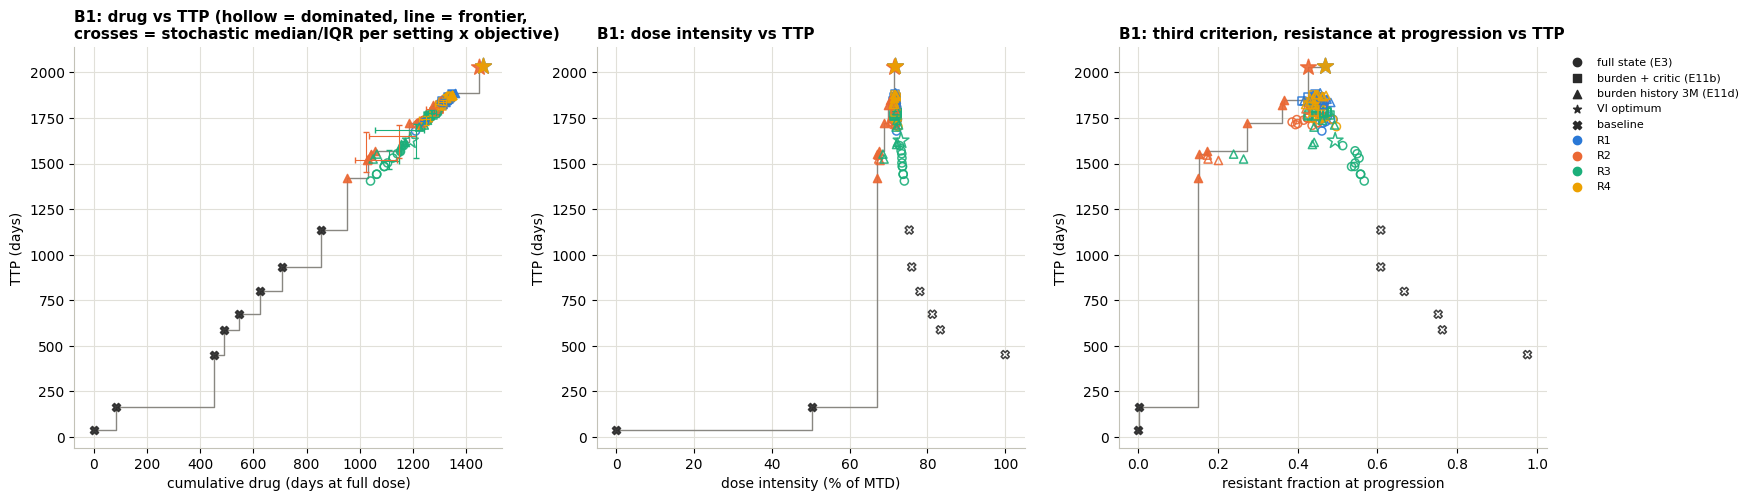

n      dose  dose_pct       TTP  share_dominated_cum_dose  share_dominated_intensity  share_dominated_resistance
group                    obj                                                                                                                   
full state (E3)          R1   10  1256.289    72.042  1743.872                      0.90                       1.00                        1.00
                         R2   10  1238.437    71.491  1726.106                      0.60                       1.00                        1.00
                         R3   10  1098.020    73.518  1493.520                      0.90                       1.00                        1.00
                         R4   10  1260.770    71.915  1750.770                      0.80                       1.00                        1.00
burden + critic (E11b)   R1   10  1329.399    71.739  1854.800                      0.70                       1.00                        1.00
                         R2   10  1292.879    71.858  1800.809                      1.00                       1.00                        1.00
                         R3   10  1281.500    71.981  1778.500                      0.70                       1.00                        1.00
                         R4   10  1324.766    71.715  1846.266                      0.80                       1.00                        1.00
burden history 3M (E11d) R1   10  1325.982    71.839  1844.775                      0.70                       1.00                        1.00
                         R2   10  1050.000    67.667  1560.019                      0.30                       0.40                        0.40
                         R3    8  1195.896    72.137  1657.896                      0.75                       1.00                        1.00
                         R4   10  1342.899    71.668  1867.899                      0.50                       0.90                        1.00
VI optimum               R1    1  1463.000    71.798  2037.671                      0.00                       0.00                        0.00
                         R2    1  1449.000    71.369  2030.281                      0.00                       0.00                        0.00
                         R3    1  1190.000    73.229  1625.036                      1.00                       1.00                        1.00
                         R4    1  1463.000    71.798  2037.671                      0.00                       0.00                        0.00
baseline                 -     8   518.432    77.026   630.432                      0.00                       0.75                        0.75

non-dominated on dose intensity vs TTP: ['baseline: None', 'baseline: IT', 'burden history 3M (E11d): R2|s1', 'burden history 3M (E11d): R2|s4', 'burden history 3M (E11d): R2|s6', 'burden history 3M (E11d): R2|s2', 'burden history 3M (E11d): R2|s9', 'burden history 3M (E11d): R2|s7', 'burden history 3M (E11d): R4|s5', 'VI optimum: VI-R2', 'VI optimum: VI-R1', 'VI optimum: VI-R4']


In [5]:
groups = {'full state (E3)': C3, 'burden + critic (E11b)': Cb, 'burden history 3M (E11d)': Cd}
KEEP = ['dose', 'dose_pct', 'TTP', 'term_fR']
rows = [dict(group=g, obj=r.obj, policy=r.policy, **r[KEEP]) for g, C_ in groups.items() for _, r in C_.ok.iterrows()]
rows += [dict(group='VI optimum', obj=k[3:], policy=k, **P0.e2.loc[k, KEEP]) for k in P0.e2.index]
rows += [dict(group='baseline', obj='-', policy=k, **P0.e1.loc[k, KEEP]) for k in P0.e1.index]
pf = pd.DataFrame(rows)
for x in ('dose', 'dose_pct', 'term_fR'):
    pf[f'dominated_{x}'] = dominated(pf[x], pf.TTP)

spread = []
for g, C_ in groups.items():
    for o in OBJECTIVES:
        ms = [rollout(Agent(C_.res[k], greedy=False, seed=1), [POP] * 50, objs=()) for k in C_.ok.policy[C_.ok.obj == o]]
        spread.append(dict(group=g, obj=o, dose=np.percentile(np.concatenate([m['dose'] for m in ms]), [25, 50, 75]),
                           TTP=np.percentile(np.concatenate([m['TTP'] for m in ms]), [25, 50, 75])))

b1 = pf.groupby(['group', 'obj'], sort=False).agg(n=('policy', 'size'), dose=('dose', 'median'), dose_pct=('dose_pct', 'median'),
                                                   TTP=('TTP', 'median'), share_dominated_cum_dose=('dominated_dose', 'mean'),
                                                   share_dominated_intensity=('dominated_dose_pct', 'mean'),
                                                   share_dominated_resistance=('dominated_term_fR', 'mean'))
MK = {'full state (E3)': 'o', 'burden + critic (E11b)': 's', 'burden history 3M (E11d)': '^', 'VI optimum': '*', 'baseline': 'X'}
fig, axs = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw=dict(wspace=.22))
for ax, x, xl in ((axs[0], 'dose', 'cumulative drug (days at full dose)'), (axs[1], 'dose_pct', 'dose intensity (% of MTD)'),
                  (axs[2], 'term_fR', 'resistant fraction at progression')):
    for _, r in pf.iterrows():
        c = COL.get(r.obj, INK); dom = r[f'dominated_{x}']
        ax.scatter(r[x], r.TTP, marker=MK[r.group], s=140 if r.group == 'VI optimum' else 34, facecolor='none' if dom else c,
                   edgecolor=c, lw=1.1, zorder=3, alpha=.9)
    fr = pf[~pf[f'dominated_{x}']].sort_values(x)
    ax.step(fr[x], fr.TTP, where='post', color=MUTED, lw=1, zorder=2)
    ax.set(xlabel=xl, ylabel='TTP (days)')
for s in spread:
    axs[0].errorbar(s['dose'][1], s['TTP'][1], xerr=[[s['dose'][1] - s['dose'][0]], [s['dose'][2] - s['dose'][1]]],
                    yerr=[[s['TTP'][1] - s['TTP'][0]], [s['TTP'][2] - s['TTP'][1]]], color=COL[s['obj']], lw=.8, capsize=2, zorder=4)
for g, m in MK.items():
    axs[2].scatter([], [], marker=m, color=INK, label=g)
for o in OBJECTIVES:
    axs[2].scatter([], [], marker='o', color=COL[o], label=o)
axs[2].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
axs[0].set_title('B1: drug vs TTP (hollow = dominated, line = frontier,\ncrosses = stochastic median/IQR per setting x objective)')
axs[1].set_title('B1: dose intensity vs TTP'); axs[2].set_title('B1: third criterion, resistance at progression vs TTP')
save('B1_pareto')
SUMMARY['B1'] = {f'{g} | {o}': {k: (round(float(v), 3) if isinstance(v, float) else int(v)) for k, v in r.items()} for (g, o), r in b1.iterrows()}
front = lambda x: [f'{g}: {k}' for g, k in pf[~pf[f'dominated_{x}']].sort_values(x)[['group', 'policy']].values]
SUMMARY['B1_frontier'] = {x: front(x) for x in ('dose', 'dose_pct', 'term_fR')}
display(b1.round(3))
print('non-dominated on dose intensity vs TTP:', front('dose_pct'))

**Reading B1.**
- **One line, not a cloud.** Every learned and VI policy runs at 71–74% dose intensity (the one exception is E11d's R2 agents, at 67.7%). TTP then rises almost linearly with cumulative drug (left panel): surviving longer simply means more weeks on drug at the same intensity. So cumulative drug is not a separate criterion here; **dose intensity is the real trade-off axis**.
- **The intensity frontier** (middle) runs: no treatment → IT → six of the ten E11d R2 agents (and one E11d R4) → VI-R2 / VI-R1 / VI-R4. Every full-state and E11b agent is dominated: some other policy has no higher intensity and more TTP.
- **R2's anomaly is a trade-off, not a failure.** In E11c/E11d the R2 memory agents had lower TTP than R1/R4, even on R2's own score. Here they give up ≈ 285 d of TTP (1560 vs 1845 d) for ≈ 4 points less intensity, and no policy beats them on both. Only 40% of them are dominated on intensity, against 90–100% for every other trained group.
- **Resistance at progression** (right): the R2 memory agents again form the frontier, ending at a resistant fraction of 0.15–0.37, against ≈ 0.40–0.57 for the other agents. The full-state R3 agents end with the *most* resistance (≈ 0.5–0.57) and less TTP, so they are dominated on both. VI-R3 is dominated on all three criteria.
- **Stochastic spread.** The crosses (50 sampled rollouts per agent) lie on the same diagonal as the greedy points: sampling moves a policy *along* the line, not off it.

**For the paper.** Read "cost of the wrong objective" as movement along one drug–TTP line. R2 does what it is asked: it buys lower intensity with TTP, Pareto-efficiently.

## 2. B2: does "coexistence is last" survive a different reward shape? [REWARD]

The ported R3 (root D12) is almost flat and discontinuous: +0.1 in a band 2.6% wide around 50:50, −0.1 near a pure tumour, 0 elsewhere, plus the −100 progression penalty. PPO sees little signal until it lands in the band. Three shapes are compared, each with the **same** progression penalty and per-step scale (±0.1):

| Name | Reward per step (f = R/N, H = entropy) | Source |
|---|---|---|
| `R3` (a) | band: +0.1 if H ≥ 0.9995 H_max, −0.1 if H < 0.05 H_max, else 0 | the existing port (E3) |
| `R3s` (b) | smooth entropy: 0.1 · (2 H / H_max − 1), so −0.1 for a pure tumour, +0.1 at 50:50 | new |
| `R3d{f*}` (c) | smooth target: 0.1 · (1 − abs(log10(f / f*))), floored at −0.1: +0.1 at f*, 0 one decade away | new; the smooth analogue of E6's band sweep |

VI is re-solved for every shape (each has its own ceiling). PPO: `R3s` 10 seeds (it replaces R3 in the comparison); `R3d` 5 seeds per f* ∈ {0.05, 0.1, 0.25, 0.5}, as in E6. The E3 R1- and R3-trained agents are re-scored on every shape.

**How to read the outcome** (doc): if a smooth R3 does much better, "R3 is last" needs refining; if it still does badly **and VI predicts the same limit**, the problem is structural, not PPO's.

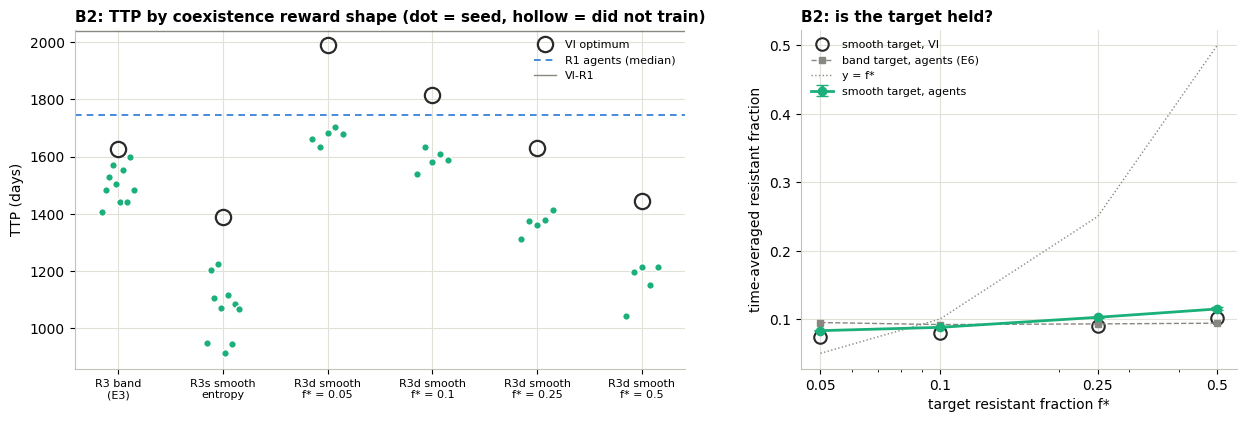

,VI_TTP,VI_mean_fR,VI_TTP_loss_vs_VI_R1,agent_TTP,agent_mean_fR,own_score,trained,loss_on_R1,R1_agents_on_this_objective,own_agents_on_this_objective
R3,1625,0.092,413,"1.49e+03 [1.45e+03, 1.55e+03]","0.0946 [0.0926, 0.0969]","0.763 [0.744, 0.774]",10/10,0.121,0.776,0.763
R3s,1387,0.107,651,"1.08e+03 [978, 1.11e+03]","0.126 [0.122, 0.136]","0.866 [0.843, 0.87]",10/10,0.325,0.88,0.866
R3d0.05,1989,0.074,48,"1.68e+03 [1.66e+03, 1.68e+03]","0.0831 [0.0824, 0.0844]","0.854 [0.852, 0.856]",5/5,0.029,0.873,0.854
R3d0.1,1814,0.08,224,"1.59e+03 [1.58e+03, 1.61e+03]","0.0879 [0.0854, 0.0891]","0.846 [0.84, 0.849]",5/5,0.076,0.869,0.846
R3d0.25,1631,0.09,406,"1.38e+03 [1.36e+03, 1.38e+03]","0.103 [0.101, 0.103]","0.822 [0.821, 0.826]",5/5,0.177,0.851,0.822
R3d0.5,1443,0.101,594,"1.2e+03 [1.15e+03, 1.21e+03]","0.115 [0.113, 0.118]","0.82 [0.818, 0.824]",5/5,0.267,0.839,0.82


In [6]:
VAR = ('R3', 'R3s') + tuple(f'R3d{f}' for f in B2_TARGETS)
OBJ2 = OBJECTIVES + VAR[1:]
vi2 = {o: P0.vi['R3'] if o == 'R3' else solve_vi(o, POP) for o in VAR}
e2b = evaluate({o: Lookahead(v) for o, v in vi2.items()}, objs=OBJ2).set_index('policy')
none2 = evaluate({'None': Const(0)}, objs=OBJ2).iloc[0]
B2 = load('B2')
AG2 = {f"{r['obj']}|s{r['seed']}": Agent(r) for r in B2} | {k: C3.ag[k] for k in C3.ev.policy if k.split('|')[0] in ('R1', 'R3')}
ev2 = split(evaluate(AG2, objs=OBJ2))
own2 = lambda G, o: (G - none2[f'G_{o}']) / (e2b.loc[o, f'G_{o}'] - none2[f'G_{o}'])
ev2['own_score'] = [own2(r[f'G_{r.obj}'], r.obj) if r.obj in VAR else np.nan for _, r in ev2.iterrows()]
ev2['score_on_R1'] = score(ev2.G_R1, 'R1', P0.floor, P0.ceil)
r1 = ev2[ev2.obj == 'R1']
tr2 = lambda o: ev2[(ev2.obj == o) & (ev2.own_score >= .7)]
tab2 = pd.DataFrame({o: dict(VI_TTP=round(e2b.loc[o, 'TTP']), VI_mean_fR=round(e2b.loc[o, 'mean_fR'], 3),
                             VI_TTP_loss_vs_VI_R1=round(P0.e2.loc['VI-R1', 'TTP'] - e2b.loc[o, 'TTP']),
                             agent_TTP=miqr(tr2(o).TTP), agent_mean_fR=miqr(tr2(o).mean_fR), own_score=miqr(ev2[ev2.obj == o].own_score),
                             trained=f"{len(tr2(o))}/{(ev2.obj == o).sum()}",
                             loss_on_R1=round(r1.score_on_R1.median() - tr2(o).score_on_R1.median(), 3),
                             R1_agents_on_this_objective=round(float(own2(r1[f'G_{o}'], o).median()), 3),
                             own_agents_on_this_objective=round(float(tr2(o).own_score.median()), 3))
                     for o in VAR}).T
SUMMARY['B2'] = {o: {k: (v if isinstance(v, str) else float(v)) for k, v in r.items()} for o, r in tab2.iterrows()}

fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw=dict(wspace=.22, width_ratios=[1.4, 1]))
for i, o in enumerate(VAR):
    d = ev2[ev2.obj == o]; good = d.own_score >= .7; jit = np.linspace(-.15, .15, len(d))
    axs[0].scatter((i + jit)[good.values], d.TTP[good], s=30, color=COL['R3'], edgecolor='white', zorder=3)
    axs[0].scatter((i + jit)[~good.values], d.TTP[~good], s=30, facecolor='none', edgecolor=COL['R3'], zorder=3)
    axs[0].plot(i, e2b.loc[o, 'TTP'], 'o', mfc='none', mec=INK, ms=11, mew=1.6, zorder=4, label='VI optimum' if i == 0 else None)
axs[0].axhline(r1.TTP.median(), color=COL['R1'], ls=(0, (4, 3)), lw=1.2, label='R1 agents (median)')
axs[0].axhline(P0.e2.loc['VI-R1', 'TTP'], color=MUTED, lw=1, label='VI-R1')
axs[0].set_xticks(range(len(VAR)), ['R3 band\n(E3)', 'R3s smooth\nentropy'] + [f'R3d smooth\nf* = {f}' for f in B2_TARGETS], fontsize=8)
axs[0].set(ylabel='TTP (days)', title='B2: TTP by coexistence reward shape (dot = seed, hollow = did not train)'); axs[0].legend(fontsize=8)
fs = np.array(B2_TARGETS)
q = np.array([np.percentile(tr2(f'R3d{f}').mean_fR, [25, 50, 75]) for f in fs])
axs[1].errorbar(fs, q[:, 1], yerr=[q[:, 1] - q[:, 0], q[:, 2] - q[:, 1]], color=COL['R3'], marker='o', capsize=4, label='smooth target, agents')
axs[1].plot(fs, [e2b.loc[f'R3d{f}', 'mean_fR'] for f in fs], 'o', mfc='none', mec=INK, ms=9, mew=1.5, label='smooth target, VI')
axs[1].plot(fs, [ORIG_SUMMARY['E6'][str(f)]['agent_mean_fR'] for f in fs], 's--', color=MUTED, ms=5, lw=1, label='band target, agents (E6)')
axs[1].plot(fs, fs, ':', color=MUTED, lw=1, label='y = f*')
axs[1].set_xscale('log'); axs[1].set_xticks(fs, [str(f) for f in fs])
axs[1].set(xlabel='target resistant fraction f*', ylabel='time-averaged resistant fraction', title='B2: is the target held?'); axs[1].legend(fontsize=8)
save('B2_r3_reward_shape')
tab2

**Reading B2.**
- **Smooth entropy (`R3s`) is worse than the band, not better.**
  - VI-R3s reaches 1387 d, 651 d below VI-R1 (the band: 413 d).
  - Its agents all train (10/10, own score 0.87), yet reach only ≈ 1080 d and lose 0.325 of R1's score (the band: 0.121).
  - Rewarding "closer to 50:50" everywhere pulls the policy toward a higher resistant fraction (VI mean f 0.107 vs 0.092), which shortens survival.
- **Smooth targets make f\* matter**, unlike E6's band, where the VI TTP was 1625–1631 d and agents sat at f ≈ 0.093 for every f\*. VI TTP now falls from 1989 d (f\* = 0.05) to 1443 d (f\* = 0.5), and the agents follow (≈ 1680 → 1200 d). At f\* = 0.05 the cost nearly vanishes (R1 loss 0.029; VI 48 d below VI-R1), because that target sits next to the fraction containment produces anyway.
- **No policy holds its target** (right panel). As f\* goes 0.05 → 0.5, the time-averaged f stays at 0.07–0.10 for VI and 0.08–0.12 for agents. VI does no better than PPO, so **the limit is in the dynamics, not in PPO** (the doc's criterion for "structural").
- **Instrumental convergence in reverse survives every shape.** R1-trained agents score *higher on each coexistence objective* than the agents trained for it: 0.776 vs 0.763 (band), 0.880 vs 0.866 (`R3s`), 0.873 vs 0.854 (f\* = 0.05) … 0.839 vs 0.820 (f\* = 0.5).

**For the paper.** "R3 is last" is not an artefact of the band's maths. Refine it: the survival cost of coexistence **scales with the target fraction**. A target at or below the fraction containment already produces (≈ 0.07–0.09) is almost free, and every higher target costs survival.

## 3. Reducing limitations: A3 grid check, A1 turnover patient, A2 equal budgets [CONFIG]

### A3: are the VI ceilings converged?

Every score is a fraction of a VI ceiling, which is a discretised optimum (root D17: 161 burden levels × 241 log-fractions). Here the grid is doubled in each dimension (321 × 481, four times the states) and all four objectives are re-solved. The doc's criterion: the ceilings (R1 2038, R2 2030, R3 1625, R4 2038 d) should move by less than 1%.

In [7]:
fine = Grid(POP['N0'], nN=321, nf=481)
rows = []
for o in OBJECTIVES:
    v = solve_vi(o, POP, grid=fine); m = rollout(Lookahead(v), [POP])
    rows.append(dict(obj=o, TTP_161x241=P0.e2.loc[f'VI-{o}', 'TTP'], TTP_321x481=m['TTP'][0],
                     G_161x241=P0.ceil[o], G_321x481=m[f'G_{o}'][0], grid_value_321x481=v['V0'], PI_iterations=v['iters']))
a3 = pd.DataFrame(rows).set_index('obj')
a3['TTP_change_%'] = 100 * (a3.TTP_321x481 / a3.TTP_161x241 - 1)
a3['span_change_%'] = [100 * ((a3.loc[o, 'G_321x481'] - P0.floor[o]) / (a3.loc[o, 'G_161x241'] - P0.floor[o]) - 1) for o in OBJECTIVES]
SUMMARY['A3'] = a3.round(4).to_dict('index')
print('largest change in a ceiling: TTP %.2f%%, normalised span %.2f%%' % (a3['TTP_change_%'].abs().max(), a3['span_change_%'].abs().max()))
a3.round(3)

largest change in a ceiling: TTP 0.36%, normalised span 0.02%


,TTP_161x241,TTP_321x481,G_161x241,G_321x481,grid_value_321x481,PI_iterations,TTP_change_%,span_change_%
obj,,,,,,,,
R1,2037.671,2037.671,28.846,28.846,28.840,8,0.000,0.000
R2,2030.281,2030.281,-93.600,-93.600,-93.566,9,0.000,0.000
R3,1625.036,1625.036,-80.597,-80.597,-80.674,14,0.000,0.000
R4,2037.671,2030.281,23.486,23.491,23.503,4,-0.363,0.023


**Reading A3.** Doubling the grid in each dimension moves no ceiling by more than 0.36% in TTP, and no normalised span by more than 0.02%. R1, R2 and R3 give identical trajectories. R4 moves from 2038 to 2030 d because R1 and R4 are almost exactly tied at the optimum, so a grid change can flip a single decision. Criterion (< 1%) met: every score here and in `experiments.ipynb` stands.

### A1: the core comparison on a patient with turnover > 0

The headline matrix was computed on two patients (PoP, and PoP with cost 0.42), **both with turnover 0** (README limitations). Turnover is where a change in behaviour would first appear: it decides whether the resistant population can shrink at all, since its per-capita rate is r_R(1 − N/K) − d_T.

**Patient.** PoP with **turnover 0.04** (cost 0). That is the E7 cohort's upper edge, below Strobl's controllability bound (0.1 for cost 0), so it still progresses under MTD (474 d), and VI-R1 stays far below the 30-year cap (≈ 3390 d), so the ceilings are valid (root D6). One parameter changes relative to PoP. Same pipeline as E3c: AT-PSC re-tuned, VI re-solved, 4 objectives × 10 seeds at 10⁶ steps, same tests.

turnover 0.04: tuned AT-PSC N_T = 1.1 N0, treat 28 of 28 d; best heuristic AT-PSC (2078 d); VI-R1 and VI-R4 grid policies identical: False


,TTP,dose_pct,mean_fR,f_holiday,G_R1,G_R2,G_R3,G_R4
policy,,,,,,,,
None,55.366,0.000,0.001,0.001,0.948,-100.303,-100.000,0.598
MTD,473.675,100.000,0.446,0.989,6.390,-101.094,-94.907,3.491
AT25,614.551,82.914,0.281,0.910,8.972,-99.638,-93.055,5.927
AT50,693.015,79.798,0.248,0.903,10.308,-99.155,-91.868,6.996
AT75,926.194,72.792,0.192,0.818,14.001,-97.654,-90.495,9.956
AT90,1103.068,69.539,0.171,0.776,16.715,-96.558,-88.730,12.059
IT,1454.217,50.061,0.037,0.144,23.272,-91.707,-86.173,17.962
AT-PSC,2078.271,58.235,0.124,0.699,31.053,-90.085,-80.903,22.676
VI-R1,3388.765,49.162,0.103,0.653,48.334,-80.977,-73.761,34.967


A1: did not train (< 0.7 of own ceiling): ['R3|s4', 'R3|s8', 'R3|s9']
Kruskal-Wallis on TTP across objectives: H = 23.44, p = 3.3e-05
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


shared state set: 13384 states, N/N0 in [0.15, 1.20]


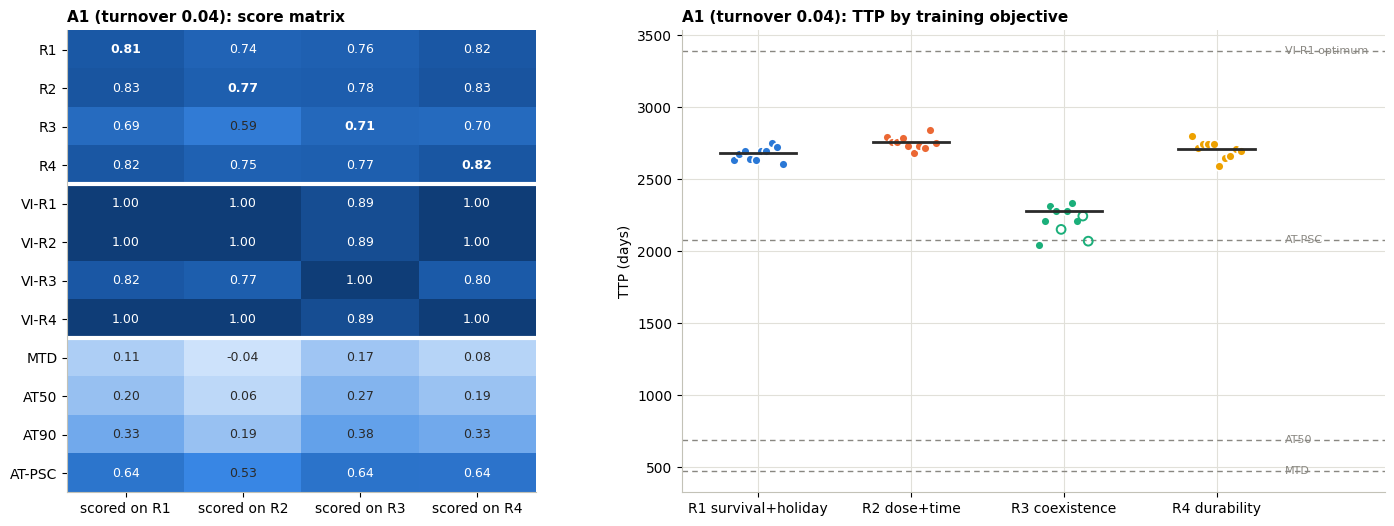

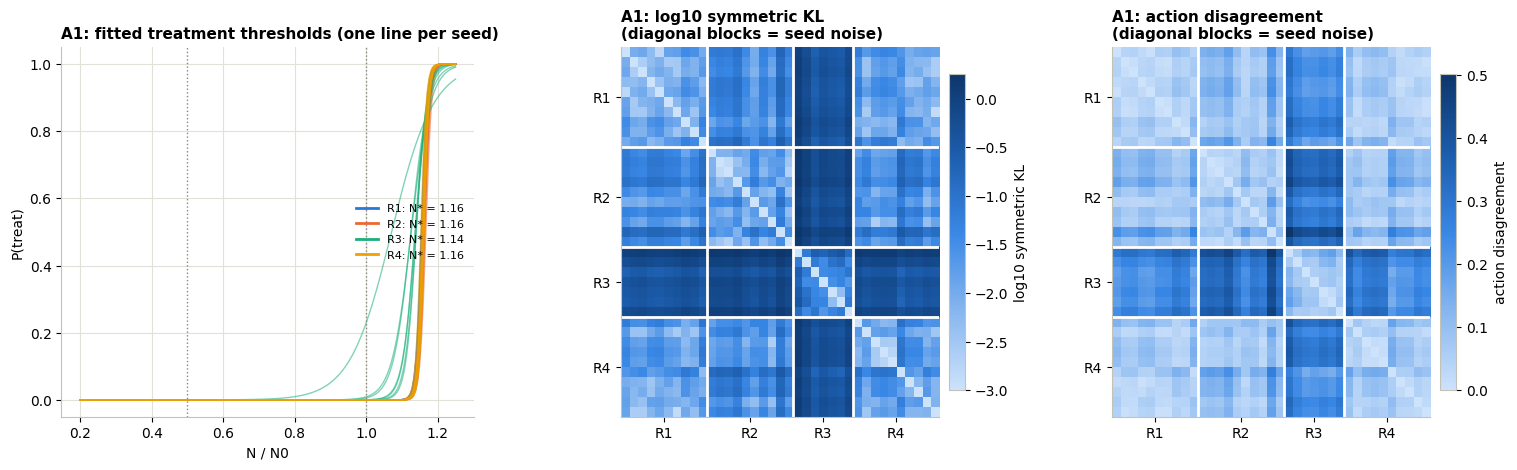

,R1,R2,R3,R4
R1,0.000,0.025,-0.046,0.007
R2,-0.020,0.000,-0.068,-0.010
R3,0.116,0.172,0.000,0.123
R4,-0.008,0.015,-0.055,0.000


,between_KL,within_KL,ratio,p_KL,between_disagree,within_disagree,p_disagree,verdict
pair,,,,,,,,
R1 vs R2,0.059,0.016,3.729,5.999e-04,0.107,0.057,5.999e-04,DIFFERENT policies
R1 vs R3,0.554,0.040,13.955,2.000e-04,0.248,0.060,2.000e-04,DIFFERENT policies
R1 vs R4,0.020,0.019,1.044,2.416e-01,0.060,0.058,1.970e-01,not distinguishable from seed noise
R2 vs R3,0.836,0.044,18.812,2.000e-04,0.342,0.073,2.000e-04,DIFFERENT policies
R2 vs R4,0.053,0.023,2.332,7.998e-04,0.093,0.067,2.799e-03,DIFFERENT policies
R3 vs R4,0.622,0.049,12.687,2.000e-04,0.275,0.075,2.000e-04,DIFFERENT policies


,"PoP (cost 0, turnover 0)",cost 0.42 (E3c),turnover 0.04 (A1)
VI-R1 TTP,2038,3683,3389
VI-R3 TTP,1625,2919,2682
VI-R4 = VI-R1 (TTP),True,True,True
TTP R1,1744,3031,2685
TTP R2,1726,3009,2757
TTP R3,1494,2498,2277
TTP R4,1751,3024,2713
R3 trained,10,5,7
R1-R3 gap (d),250,533,407.2
wrong-objective cost of R3,0.176,0.166,0.172


In [8]:
XT = ref(TURNP)
print(f"turnover 0.04: tuned AT-PSC N_T = {XT.psc[0]} N0, treat {XT.psc[1]} of 28 d; best heuristic {XT.best_h} "
      f"({XT.e1.loc[XT.best_h, 'TTP']:.0f} d); VI-R1 and VI-R4 grid policies identical: {(XT.vi['R1']['pol'] == XT.vi['R4']['pol']).all()}")
display(pd.concat([XT.e1, XT.e2])[['TTP', 'dose_pct', 'mean_fR', 'f_holiday', 'G_R1', 'G_R2', 'G_R3', 'G_R4']].round(3))
CT = cross('A1', load('A1'), XT, TURNP)
plot_cross(CT, XT, 'A1 (turnover 0.04)'); save('A1_cross_evaluation')
plot_divergence(CT.ps, 'A1'); save('A1_policy_divergence')
display(CT.loss.round(3)); display(CT.ps['div'])


def from_orig(e4, e3, div, vi_ttp):
    # the same comparison numbers, read from the original summary.json
    S = ORIG_SUMMARY
    return {'VI-R1 TTP': vi_ttp('R1'), 'VI-R3 TTP': vi_ttp('R3'), 'VI-R4 = VI-R1 (TTP)': vi_ttp('R4') == vi_ttp('R1'),
            **{f'TTP {o}': S[e4]['TTP_median'][o] for o in OBJECTIVES}, 'R3 trained': S[e3]['R3']['trained'],
            'R1-R3 gap (d)': S[e4]['TTP_median']['R1'] - S[e4]['TTP_median']['R3'],
            'wrong-objective cost of R3': max(v['R3'] for v in S[e4]['loss'].values()),
            'max cost among R1/R2/R4': max(S[e4]['loss'][a][b] for a in ('R1', 'R2', 'R4') for b in ('R1', 'R2', 'R4')),
            'pairs DIFFERENT': sum(v['verdict'] == 'DIFFERENT policies' for v in S[div].values()), 'R1 vs R4': S[div]['R1 vs R4']['verdict']}


dA1 = digest(CT)
a1 = pd.DataFrame({
    'PoP (cost 0, turnover 0)': from_orig('E4', 'E3', 'E5_divergence', lambda o: ORIG_SUMMARY['E2'][o]['TTP']),
    'cost 0.42 (E3c)': from_orig('E4c', 'E3c', 'E5c_divergence', lambda o: ORIG_SUMMARY['E3c_baselines_VI'][f'VI-{o}']),
    'turnover 0.04 (A1)': {'VI-R1 TTP': round(XT.e2.loc['VI-R1', 'TTP']), 'VI-R3 TTP': round(XT.e2.loc['VI-R3', 'TTP']),
                           'VI-R4 = VI-R1 (TTP)': round(XT.e2.loc['VI-R4', 'TTP']) == round(XT.e2.loc['VI-R1', 'TTP']),
                           **{f'TTP {o}': round(dA1['TTP'][o]) for o in OBJECTIVES}, 'R3 trained': dA1['trained']['R3'],
                           'R1-R3 gap (d)': dA1['R1_R3_gap'], 'wrong-objective cost of R3': round(float(CT.loss.loc['R3'].max()), 3),
                           'max cost among R1/R2/R4': dA1['max_wrong_cost_R1R2R4'],
                           'pairs DIFFERENT': sum(v == 'DIFFERENT policies' for v in dA1['verdicts'].values()),
                           'R1 vs R4': dA1['verdicts']['R1 vs R4']}})
SUMMARY['A1'] = dA1 | dict(VI_TTP={o: round(float(XT.e2.loc[f'VI-{o}', 'TTP'])) for o in OBJECTIVES}, psc=list(XT.psc),
                           best_heuristic=[XT.best_h, round(float(XT.e1.loc[XT.best_h, 'TTP']))])
a1

**Reading A1.** Turnover 0.04 lengthens everything: MTD 474 d, VI-R1 3389 d. The best heuristic is the re-tuned AT-PSC (N_T = 1.1 N₀, treat 28 of 28 d, 2078 d), i.e. pure containment at a threshold. Every headline result reproduces (table above, three patients side by side):
- **VI:** R1, R2 and R4 give the same trajectory (3389 d), and VI-R3 is 21% shorter. The R1 and R4 grid policies differ only off-trajectory.
- **Agents:** R1 2685, R2 2757, R4 2713, R3 2277 d. R3 trains on 7/10 seeds (as feared in F7: longer episodes at a fixed budget). R1–R3 gap 407 d. Own scores are 0.70–0.82, against 0.76–0.87 on PoP, for the same reason.
- **Cost of the wrong objective:** R3 up to 0.172 (PoP 0.176, cost 0.42: 0.166); R1/R2/R4 up to 0.025.
- **Policy space:** 5 of 6 pairs DIFFERENT. R1 vs R4 is not distinguishable from seed noise (disagreement 1.04× within-objective).
- **Instrumental convergence:** fails (one-sided p = 1).

**For the paper.** The README limitation "both reference patients have turnover 0" is closed: three patients, spanning cost and turnover, give the same matrix shape.

### A2: give every observation setting the same 3× budget

Only the memory agents (E11d) got 3×10⁶ steps (root D43), so comparisons between E11d and the full-state (E3) or burden-only (E11b) agents differ in budget as well as in observation. Root D41 also notes that the full-state agents' ≈ 15% gap to VI may be learning inefficiency rather than missing information. Here the **identical** E3 and E11b configurations are retrained at 3×10⁶ steps (all four objectives, 10 seeds). The 1M versions are kept, so 1M vs 3M isolates budget, and the three 3M settings can now be compared at equal budget.

A2full: did not train (< 0.7 of own ceiling): none
Kruskal-Wallis on TTP across objectives: H = 22.17, p = 6e-05
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


shared state set: 7712 states, N/N0 in [0.19, 1.20]


A2burden: did not train (< 0.7 of own ceiling): none
Kruskal-Wallis on TTP across objectives: H = 16.10, p = 0.0011
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


shared state set: 5396 states, N/N0 in [0.19, 1.20]


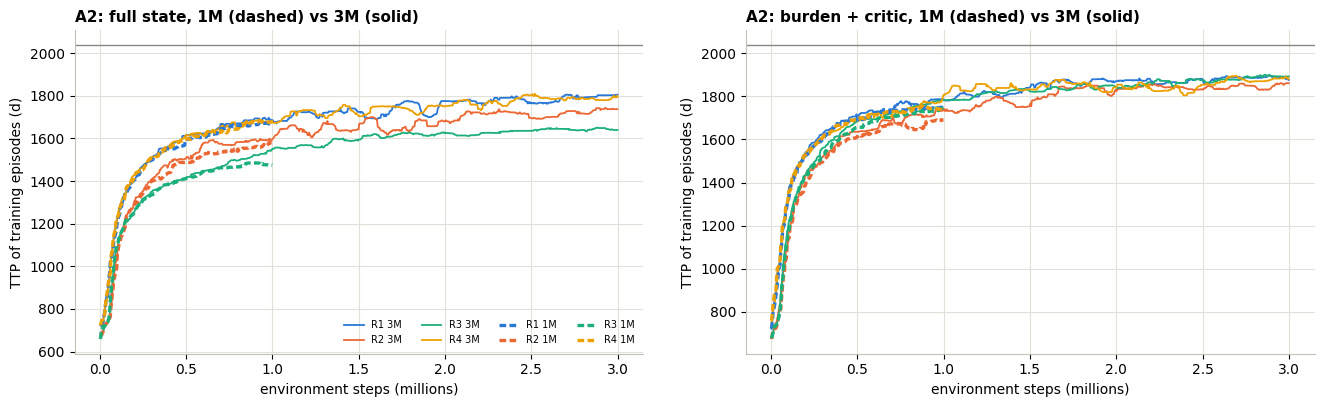

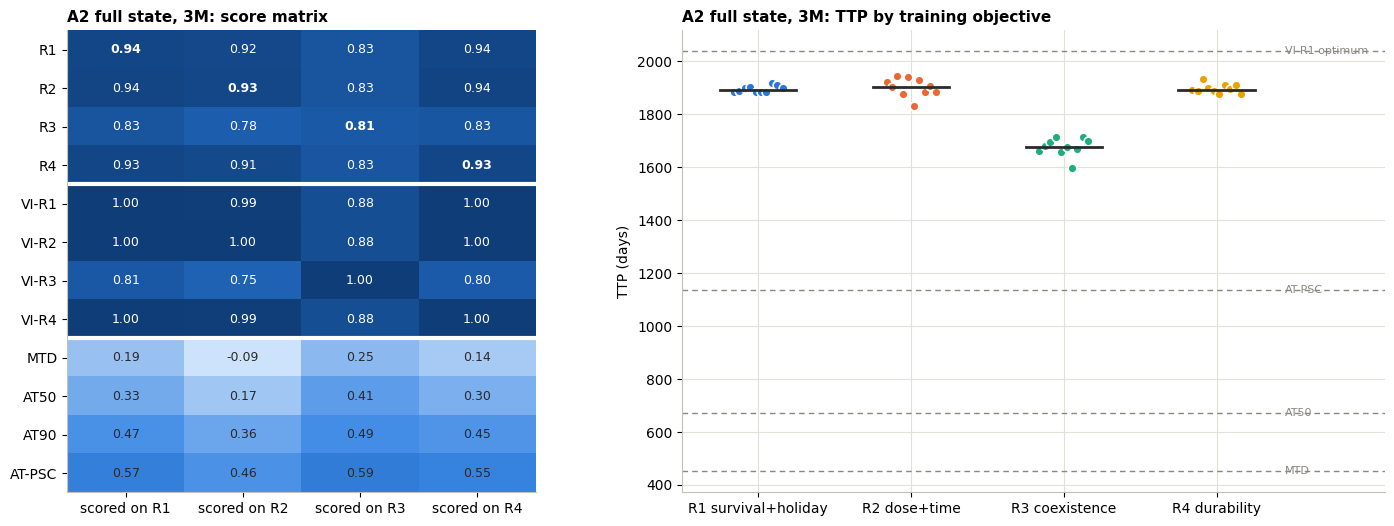

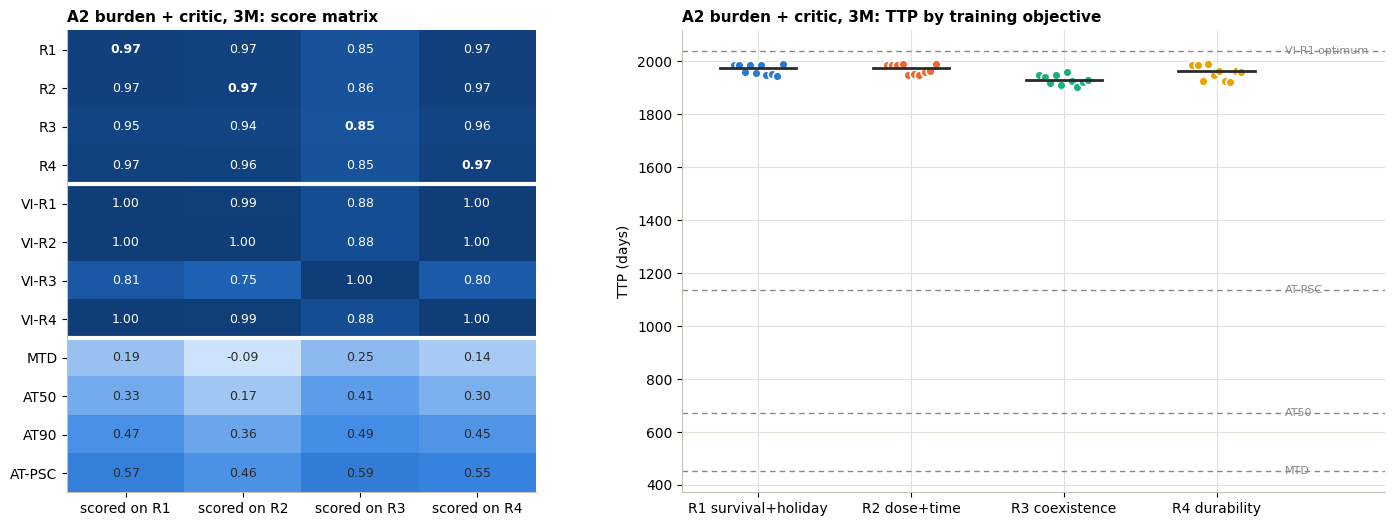

TTP R1    TTP R2    TTP R3    TTP R4  score R1  score R2  score R3  score R4  R3 trained  R1-R3 gap (d)  max wrong-objective cost  max cost among R1/R2/R4
full state              1M  1743.872  1726.106  1493.520  1750.770     0.867     0.848     0.763     0.868        10.0          250.4                     0.176                    0.017
                        3M  1892.747  1904.055  1677.848  1892.190     0.936     0.931     0.807     0.934        10.0          214.9                     0.154                    0.017
burden + critic         1M  1854.800  1800.809  1778.500  1846.266     0.919     0.860     0.798     0.914        10.0           76.3                     0.035                    0.025
                        3M  1973.399  1974.173  1927.423  1961.660     0.973     0.966     0.849     0.968        10.0           46.0                     0.023                    0.006
burden history + critic 1M  1725.653  1472.788  1571.604  1731.222     0.859     0.818     0.710     0.859         6.0          154.0                     0.105                    0.105
                        3M  1844.775  1560.019  1657.896  1867.899     0.915     0.872     0.803     0.922         8.0          186.9                     0.133                    0.118

,full 3M,burden + critic 3M,history 3M (E11d),"full vs burden, Mann-Whitney p"
R1,1892.747,1973.399,1844.775,2.000e-04
R2,1904.055,1974.173,1560.019,2.000e-04
R3,1677.848,1927.423,1657.896,2.000e-04
R4,1892.190,1961.660,1867.899,4.000e-04


between-objective disagreement as a multiple of seed noise:


,full 1M,full 3M,burden+critic 1M,burden+critic 3M,history 3M (E11d),verdict full 3M,verdict burden+critic 3M
R1 vs R2,2.75,2.29,3.27,0.95,1.61,DIFFERENT policies,not distinguishable from seed noise
R1 vs R3,3.78,6.13,4.23,2.34,1.29,DIFFERENT policies,DIFFERENT policies
R1 vs R4,1.11,0.95,1.03,1.01,1.07,not distinguishable from seed noise,not distinguishable from seed noise
R2 vs R3,4.84,7.84,1.51,2.47,1.22,DIFFERENT policies,DIFFERENT policies
R2 vs R4,2.11,2.37,1.84,1.07,1.67,DIFFERENT policies,not distinguishable from seed noise
R3 vs R4,3.71,5.99,2.54,1.73,1.41,DIFFERENT policies,DIFFERENT policies


In [9]:
A2 = load('A2')
Cf3 = cross('A2full', [r for r in A2 if r['obs'] == 'full'], P0, POP)
Cb3 = cross('A2burden', [r for r in A2 if r['obs'] == 'burden'], P0, POP)
SET = {'full state': (C3, Cf3), 'burden + critic': (Cb, Cb3), 'burden history + critic': (Cc, Cd)}
DG = {(s_, b): digest(C_) for s_, pair in SET.items() for b, C_ in zip(('1M', '3M'), pair)}
a2 = pd.DataFrame({k: {**{f'TTP {o}': d['TTP'][o] for o in OBJECTIVES}, **{f'score {o}': d['own_score'][o] for o in OBJECTIVES},
                       'R3 trained': d['trained']['R3'], 'R1-R3 gap (d)': d['R1_R3_gap'], 'max wrong-objective cost': d['max_wrong_cost'],
                       'max cost among R1/R2/R4': d['max_wrong_cost_R1R2R4']} for k, d in DG.items()}).T
mw = pd.DataFrame({o: {'full 3M': Cf3.ok[Cf3.ok.obj == o].TTP.median(), 'burden + critic 3M': Cb3.ok[Cb3.ok.obj == o].TTP.median(),
                       'history 3M (E11d)': Cd.ok[Cd.ok.obj == o].TTP.median(),
                       'full vs burden, Mann-Whitney p': stats.mannwhitneyu(Cf3.ok[Cf3.ok.obj == o].TTP, Cb3.ok[Cb3.ok.obj == o].TTP).pvalue}
                   for o in OBJECTIVES}).T
ratio_o = lambda key: {k: round(v['between_disagree'] / v['within_disagree'], 2) for k, v in ORIG_SUMMARY[key].items()}
ratio_n = lambda C_: (C_.ps['div'].between_disagree / C_.ps['div'].within_disagree).round(2)
pv = pd.DataFrame({'full 1M': ratio_o('E5_divergence'), 'full 3M': ratio_n(Cf3), 'burden+critic 1M': ratio_o('E11b_divergence'),
                   'burden+critic 3M': ratio_n(Cb3), 'history 3M (E11d)': ratio_o('E11d_divergence'),
                   'verdict full 3M': Cf3.ps['div'].verdict, 'verdict burden+critic 3M': Cb3.ps['div'].verdict})
SUMMARY['A2'] = {f'{s_} {b}': d for (s_, b), d in DG.items()}
SUMMARY['A2_equal_budget_TTP'] = mw.round(4).to_dict('index')

fig, axs = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw=dict(wspace=.18))
for ax, (s_, (c1, c3)) in zip(axs, list(SET.items())[:2]):
    for C_, ls, lw, z in ((c3, '-', 1.3, 2), (c1, (0, (2, 1)), 2.4, 3)):   # 1M on top; rolling median over 25 updates (~100k steps)
        for o in OBJECTIVES:
            cur = np.array([r['curve'][:, 1] for r in C_.res.values() if r['obj'] == o]); x = next(iter(C_.res.values()))['curve'][:, 0] / 1e6
            ax.plot(x, pd.Series(np.nanmedian(cur, 0)).rolling(25, min_periods=1, center=True).median(), color=COL[o], ls=ls, lw=lw,
                    zorder=z, label=f'{o} {"3M" if C_ is c3 else "1M"}')
    ax.axhline(P0.e2.loc['VI-R1', 'TTP'], color=MUTED, lw=1)
    ax.set(xlabel='environment steps (millions)', ylabel='TTP of training episodes (d)', title=f'A2: {s_}, 1M (dashed) vs 3M (solid)')
axs[0].legend(ncol=4, fontsize=7, loc='lower right')
save('A2_budget_curves')
plot_cross(Cf3, P0, 'A2 full state, 3M'); save('A2_full3M_cross_evaluation')
plot_cross(Cb3, P0, 'A2 burden + critic, 3M'); save('A2_burden3M_cross_evaluation')
display(a2.round(3)); display(mw.round(4))
print('between-objective disagreement as a multiple of seed noise:')
pv

**Reading A2.**
- **Budget explains part of root D41's gap to VI.** Full-state agents go from 0.87 to 0.94 of their ceilings (R1 1744 → 1893 d), and burden + critic from 0.92 to 0.97 (R1 1855 → 1973 d, 97% of VI-R1).
- **At equal budget, observation still decides.** At 3M the ranking is **burden + critic > full state > burden history** for every objective (full vs burden + critic, Mann–Whitney p ≤ 4·10⁻⁴). So E11b's "burden-only beats full state" is not a budget artefact, and the memory agents (E11d) are the weakest setting at equal budget.
- **With full state, more training sharpens the objectives.**
  - Between-objective disagreement grows: R1 vs R3 from 3.8× to 6.1× seed noise, R2 vs R3 from 4.8× to 7.8×.
  - All five pairs stay DIFFERENT, and R1 vs R4 stays at noise (0.95×).
  - R3's cost falls only from 0.176 to 0.154, and the R1–R3 gap from 250 to 215 d.
  - Divergence and "R3 last" are therefore not under-training artefacts.
- **With a burden-only actor, the objectives nearly collapse at 3M.** The R1–R3 gap is 46 d, the largest wrong-objective cost is 0.023, and only the three pairs involving R3 still differ. That actor never sees the resistant fraction, so it cannot pursue what R3 rewards, whatever it is trained on.
- **Curves.** With full state, R3 plateaus well below the other objectives (≈ 1650 d). With burden + critic, all four converge together near 1900 d.

**For the paper.** Finding F-e ("observation matters more than objective") survives equal budgets, and gets sharper: *what the policy can see* bounds *how different the objectives can make it*.

## 4. C1: where do the objectives coincide? A cost × turnover map [CONFIG, VI-only]

Replace "R1 ≡ R4 on two patients" with "R1 ≡ R4 in this region". On a 5 × 5 grid over cost ∈ [0, 0.4] and turnover ∈ [0, 0.04] (the E7 cohort box, every patient below Strobl's bound, so every patient progresses), solve VI for R1–R4 at every point (seconds each) and compute, from the optima alone:
- **R1 vs R4**: the share of states visited by either optimum on which their actions differ;
- **R3's survival penalty**: 1 − TTP(VI-R3) / TTP(VI-R1);
- **R3's wrong-objective cost**: the largest loss of VI-R3 on another objective's normalised score (1 − score, since each optimum scores 1 on its own objective);
- **coexistence controllability**: the share of weeks VI-R3 spends inside its +0.1 band.

PPO is then trained only at selected points. A1 (cost 0, turnover 0.04) is such a point, chosen at the box edge where turnover is largest.

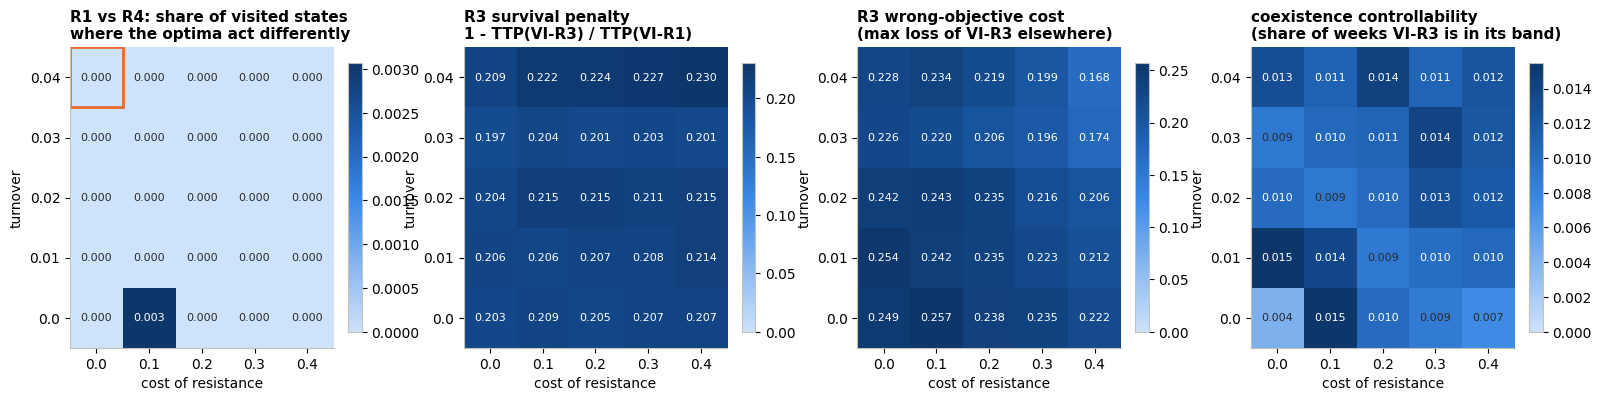

{'capped_points': 0,
 'R1_R4_disagree_range': [0.0, 0.0031],
 'R3_TTP_penalty_range': [0.1968, 0.23],
 'R3_wrong_cost_range': [0.1678, 0.2565],
 'R1R2R4_wrong_cost_range': [0.0, 0.0191],
 'R3_band_time_range': [0.0043, 0.0154]}

In [10]:
cc1, tt1 = (0.0, 0.1, 0.2, 0.3, 0.4), (0.0, 0.01, 0.02, 0.03, 0.04)
rows = []
for u in tt1:
    for c in cc1:
        p, pB = patient(c, u), stack(patient(c, u))
        vis = {o: solve_vi(o, p) for o in OBJECTIVES}
        ms = {o: rollout(Lookahead(v), [p], record=True) for o, v in vis.items()}
        none = rollout(Const(0), [p])
        if any(m['TTP'][0] >= CFG['tmax'] for m in ms.values()):
            rows.append(dict(cost=c, turnover=u, capped=True)); continue
        sc = lambda o, o2: (ms[o][f'G_{o2}'][0] - none[f'G_{o2}'][0]) / (ms[o2][f'G_{o2}'][0] - none[f'G_{o2}'][0])
        X = np.concatenate([np.c_[ms[o]['traj']['S'][:, 0], ms[o]['traj']['R'][:, 0]] for o in ('R1', 'R4')])
        tr3 = ms['R3']['traj']
        rows.append(dict(cost=c, turnover=u, capped=False, **{f'TTP_{o}': ms[o]['TTP'][0] for o in OBJECTIVES},
                         R1_R4_disagree=float(np.mean(Lookahead(vis['R1'])(X[:, 0], X[:, 1], 0, pB) != Lookahead(vis['R4'])(X[:, 0], X[:, 1], 0, pB))),
                         R3_TTP_penalty=1 - ms['R3']['TTP'][0] / ms['R1']['TTP'][0],
                         R3_wrong_cost=max(1 - sc('R3', o2) for o2 in ('R1', 'R2', 'R4')),
                         R1R2R4_wrong_cost=max(1 - sc(a, b) for a in ('R1', 'R2', 'R4') for b in ('R1', 'R2', 'R4') if a != b),
                         R3_band_time=float(np.mean(entropy(tr3['S'][:, 0], tr3['R'][:, 0]) >= 0.9995 * H2MAX))))
c1 = pd.DataFrame(rows)
c1.to_csv(f'{RES}/C1_map.csv', index=False)

fig, axs = plt.subplots(1, 4, figsize=(19, 3.9), gridspec_kw=dict(wspace=.35))
for ax, col, title in ((axs[0], 'R1_R4_disagree', 'R1 vs R4: share of visited states\nwhere the optima act differently'),
                       (axs[1], 'R3_TTP_penalty', 'R3 survival penalty\n1 - TTP(VI-R3) / TTP(VI-R1)'),
                       (axs[2], 'R3_wrong_cost', 'R3 wrong-objective cost\n(max loss of VI-R3 elsewhere)'),
                       (axs[3], 'R3_band_time', 'coexistence controllability\n(share of weeks VI-R3 is in its band)')):
    Z = c1.pivot(index='turnover', columns='cost', values=col).loc[list(tt1), list(cc1)].values.astype(float)
    im = ax.imshow(Z, origin='lower', cmap=BLUES, aspect='auto', vmin=0, vmax=max(np.nanmax(Z), 1e-3))
    for i in range(len(tt1)):
        for j in range(len(cc1)):
            ax.text(j, i, 'cap' if np.isnan(Z[i, j]) else f'{Z[i, j]:.3f}', ha='center', va='center', fontsize=8,
                    color='white' if Z[i, j] > .6 * np.nanmax(Z) else INK)
    ax.set_xticks(range(len(cc1)), cc1); ax.set_yticks(range(len(tt1)), tt1); ax.grid(False)
    ax.set(xlabel='cost of resistance', ylabel='turnover', title=title); fig.colorbar(im, ax=ax, fraction=.046)
axs[0].add_patch(plt.Rectangle((-.5, len(tt1) - 1.5), 1, 1, fill=False, ec=COL['R2'], lw=2))
save('C1_cost_turnover_map')
SUMMARY['C1'] = dict(capped_points=int(c1.capped.sum()), **{f'{k}_range': [round(float(c1[k].min()), 4), round(float(c1[k].max()), 4)]
                     for k in ('R1_R4_disagree', 'R3_TTP_penalty', 'R3_wrong_cost', 'R1R2R4_wrong_cost', 'R3_band_time')})
SUMMARY['C1']

**Reading C1.** All 25 patients progress (none capped), so every ceiling is valid.
- **R1 vs R4:** the optima act identically on every visited state at 24 of 25 points, and on all but 0.3% of them at the last (cost 0.1, turnover 0).
- **R3's survival penalty:** 20–23% everywhere, largest (0.23) at the high-cost, high-turnover corner.
- **R3's wrong-objective cost:** 0.17–0.26, smallest toward high cost and turnover (0.168 at the far corner).
- **Among R1/R2/R4:** at most 0.019.
- **Coexistence controllability:** VI-R3 spends only 0.4–1.5% of weeks inside its band at any point.

**For the paper.** "R1 ≡ R4" and "R3 last" hold over the whole E7 cohort box (cost 0–0.4, turnover 0–0.04, everything below Strobl's controllability bound), not just at two patients. A1's PPO patient (outlined) is the corner where turnover is largest.

## 5. Changing the action space: B3 → D1 → D2 → D3 → D4

### B3: how often do the existing policies switch dose? [ANALYSIS]

Before building a switching penalty (D4), count dose changes along each greedy PoP trajectory. **Decision rule (decisions F9):** if the containment policies switch on more than 25% of their weekly decisions, D4 is worth running.

In [11]:
b3 = switch_stats({**P0.vip, **P0.base})
ag_sw = pd.concat({g: split(switch_stats({k: C_.ag[k] for k in C_.ok.policy}).reset_index()) for g, C_ in groups.items()})
b3a = ag_sw.groupby([ag_sw.index.get_level_values(0), 'obj']).agg(switch_share=('switch_share', 'median'), per_year=('per_year', 'median'))
RUN_D4 = b3.loc[[f'VI-{o}' for o in ('R1', 'R2', 'R4')], 'switch_share'].min() > .25
SUMMARY['B3'] = dict(policies=b3[['switches', 'switch_share', 'per_year']].round(3).to_dict('index'),
                     agents={f'{g} | {o}': r.round(3).to_dict() for (g, o), r in b3a.iterrows()}, run_D4=bool(RUN_D4))
display(b3[['switches', 'decisions', 'switch_share', 'per_year']].round(3))
print('D4 (switching penalty) warranted:', RUN_D4)
b3a.round(3)

,switches,decisions,switch_share,per_year
policy,,,,
VI-R1,156,292,0.536,27.944
VI-R2,158,291,0.545,28.405
VI-R3,101,233,0.435,22.686
VI-R4,156,292,0.536,27.944
None,0,6,0.000,0.000
MTD,0,65,0.000,0.000
AT25,2,84,0.024,1.242
AT50,4,97,0.042,2.169
AT75,10,115,0.088,4.573


D4 (switching penalty) warranted: True


switch_share  per_year
                         obj                        
burden + critic (E11b)   R1          0.533    27.716
                         R2          0.532    27.713
                         R3          0.531    27.706
                         R4          0.533    27.747
burden history 3M (E11d) R1          0.538    28.007
                         R2          0.586    30.525
                         R3          0.530    27.521
                         R4          0.541    28.186
full state (E3)          R1          0.532    27.678
                         R2          0.543    28.265
                         R3          0.522    27.142
                         R4          0.535    27.831

**Reading B3.**
- **The optima chatter.** VI-R1/R2/R4 change dose on 54% of weekly decisions (≈ 28 switches a year; VI-R3 44%): they toggle on and off along the threshold line.
- **The agents do the same** in every observation setting: 52–59% of decisions, 27–31 switches a year.
- **The heuristics switch far less:** 0–22% of decisions (AT-PSC 6 a year, AT50 2 a year).

54% is far above the 25% gate, so D4 runs. A weekly on/off schedule is the main practical gap between the optimal (or learned) policies and the clinical heuristics.

### D1: three doses, {0, 0.5, 1} [ENV]

The ODE needs no change: the drug term is (1 − d̂_D·D) with D ∈ [0, 1], so D = 0.5 is already valid. The kill factor 1 − 1.5·D is **zero at D = 2/3**. So D = 0.5 *slows* sensitive growth (factor 0.25) but never reverses it, while D = 1 shrinks the sensitive population. Only the action set changes:
- **VI:** 2 actions become 3 (`solve_vi(..., actions=)`).
- **PPO:** the Bernoulli policy becomes a categorical over the 3 doses (`train(..., actions=)`), with the same network, budget, entropy coefficient and seeds.
- **Analysis:** P(treat) becomes P(D > 0) for the threshold fit. Divergence is the KL between dose distributions and disagreement on the most likely dose; both reduce exactly to the originals for two doses.

**Design choices (decisions F11).** No per-objective dose weights: R2 already charges D directly. D = 0.5 does **not** earn R1's holiday bonus, since only a true holiday (D = 0) does. The proportional variant (`R1p`, bonus 0.05·(1 − D)) is solved with VI as a check.

**Hypotheses** (to test, not assumed):
- H1: low dose improves containment;
- H2: the objectives become more similar, or new differences appear;
- H3: coexistence becomes easier to control.

**Stage 1** validates the doses, **Stage 2** extends VI (sanity check: every 3-dose ceiling ≥ its 2-dose ceiling, since the action set is a superset), and **Stages 3–4** train PPO and repeat the central comparison.

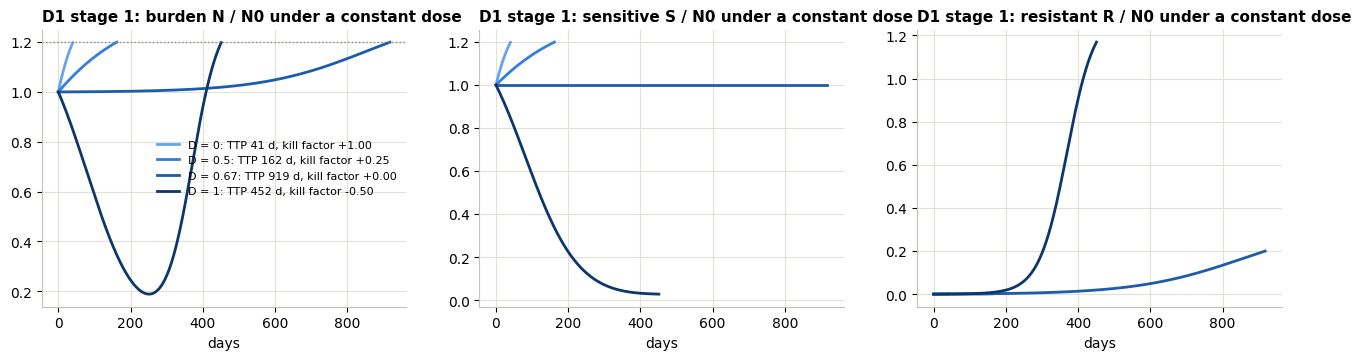

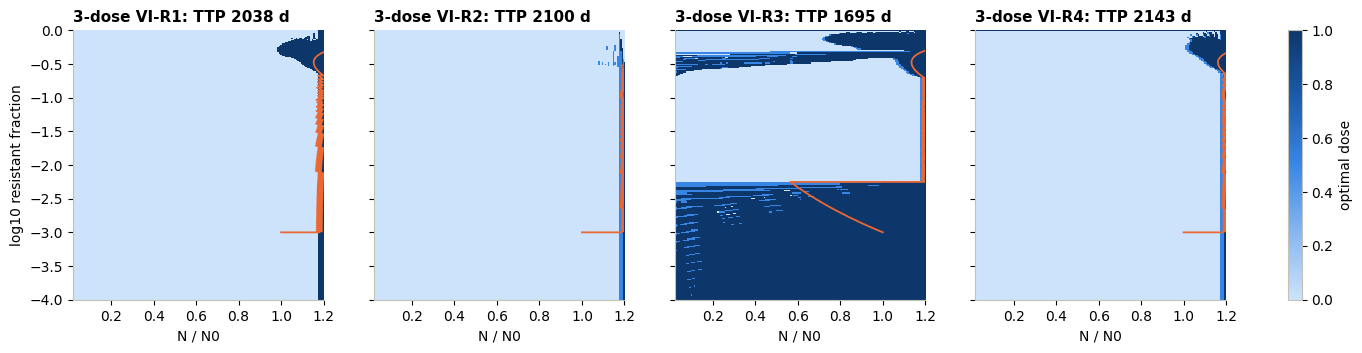

,G_2dose,G_3dose,TTP_2dose,TTP_3dose,dose_2dose,dose_3dose,f_holiday_3dose,share_half_dose,switches_2dose,switches_3dose
obj,,,,,,,,,,
R1,28.846,28.846,2037.671,2037.671,1463.0,1463.0,0.469,0.000,156.0,156.0
R2,-93.600,-93.169,2030.281,2100.136,1449.0,1480.5,0.368,0.555,158.0,209.0
R3,-80.597,-79.808,1625.036,1695.425,1190.0,1239.0,0.492,0.428,101.0,142.0
R4,23.486,24.612,2037.671,2142.852,1463.0,1533.0,0.454,0.534,156.0,203.0
R1p (proportional bonus),NaN,NaN,NaN,2142.852,NaN,1533.0,0.454,0.534,NaN,NaN


In [12]:
# Stage 1: constant doses on the PoP patient
fig, axs = plt.subplots(1, 3, figsize=(16, 3.6), sharex=True)
for d, shade in ((0.0, .35), (0.5, .55), (2 / 3, .75), (1.0, 1.0)):
    m = rollout(Const(d), [POP], interval=1, record=True, objs=())
    tr = m['traj']; S, R = tr['S'][:, 0] / POP['N0'], tr['R'][:, 0] / POP['N0']
    for ax, y in zip(axs, (S + R, S, R)):
        ax.plot(tr['t'], y, color=BLUES(shade), label=f'D = {d:.2g}: TTP {m["TTP"][0]:.0f} d, kill factor {1 - 1.5 * d:+.2f}')
for ax, t in zip(axs, ('burden N / N0', 'sensitive S / N0', 'resistant R / N0')):
    ax.set(xlabel='days', title=f'D1 stage 1: {t} under a constant dose')
axs[0].axhline(CFG['prog'], color=MUTED, ls=':', lw=1); axs[0].legend(fontsize=8)
save('D1_stage1_constant_doses')

# Stage 2: three-action VI
X3 = ref(POP, acts=DOSES3)
rows = []
for o in OBJECTIVES:
    m2, m3 = rollout(P0.vip[f'VI-{o}'], [POP], record=True), rollout(X3.vip[f'VI-{o}'], [POP], record=True)
    D2_, D3_ = m2['traj']['D'][:, 0], m3['traj']['D'][:, 0]
    rows.append(dict(obj=o, G_2dose=P0.ceil[o], G_3dose=X3.ceil[o], TTP_2dose=m2['TTP'][0], TTP_3dose=m3['TTP'][0],
                     dose_2dose=m2['dose'][0], dose_3dose=m3['dose'][0], f_holiday_3dose=m3['f_holiday'][0],
                     share_half_dose=float(np.mean(D3_ == .5)), switches_2dose=int((np.diff(D2_) != 0).sum()),
                     switches_3dose=int((np.diff(D3_) != 0).sum())))
d1vi = pd.DataFrame(rows).set_index('obj')
span = pd.Series({o: P0.ceil[o] - P0.floor[o] for o in OBJECTIVES})
assert ((d1vi.G_3dose - d1vi.G_2dose) / span > -0.005).all(), 'a superset of actions cannot lower the optimum beyond grid error'
# R1p: holiday bonus in proportion to the dose withheld. Identical to R1 for binary doses (check), then solved with 3 doses
assert np.isclose(rollout(Lookahead(solve_vi('R1p', POP)), [POP], objs=('R1p',))['G_R1p'][0], P0.ceil['R1'])
m1p = rollout(Lookahead(solve_vi('R1p', POP, actions=DOSES3)), [POP], record=True, objs=('R1p',))
d1vi.loc['R1p (proportional bonus)', ['TTP_3dose', 'dose_3dose', 'share_half_dose', 'f_holiday_3dose']] = \
    [m1p['TTP'][0], m1p['dose'][0], float(np.mean(m1p['traj']['D'][:, 0] == .5)), m1p['f_holiday'][0]]
SUMMARY['D1_VI'] = d1vi.round(4).to_dict('index')

fig, axs = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
g = X3.vi['R1']['grid']
for ax, o in zip(axs, OBJECTIVES):
    im = ax.imshow(np.asarray(DOSES3)[X3.vi[o]['pol']].T, origin='lower', aspect='auto', cmap=BLUES, vmin=0, vmax=1, interpolation='nearest',
                   extent=[g.N[0] / POP['N0'], g.N[-1] / POP['N0'], g.lf[0], g.lf[-1]])
    tr = rollout(X3.vip[f'VI-{o}'], [POP], record=True, objs=())['traj']; N = tr['S'][:, 0] + tr['R'][:, 0]
    ax.plot(N / POP['N0'], np.log10(tr['R'][:, 0] / N), color=COL['R2'], lw=1.3)
    ax.set_title(f'3-dose VI-{o}: TTP {X3.e2.loc[f"VI-{o}", "TTP"]:.0f} d'); ax.set_xlabel('N / N0'); ax.grid(False)
axs[0].set_ylabel('log10 resistant fraction'); fig.colorbar(im, ax=axs, label='optimal dose', fraction=.02)
save('D1_vi_policy_maps')
d1vi.round(3)

**Reading D1, stages 1–2.**
- **Stage 1 (constant doses).**
  - D = 0.5 slows sensitive growth (progression at 162 d).
  - D = 2/3 holds S exactly flat, and progression comes only after 919 d, through slow resistant growth. That is twice MTD's 452 d, although this dose kills nothing.
  - D = 1 shrinks S but releases R.
- **Stage 2 (three-dose VI).** Every ceiling rises except R1's: R2 +70 d (2100), R3 +70 d (1695), R4 +105 d (2143 vs 2038). R2, R3 and R4 use the half dose on 43–56% of weeks, for R2/R4 in a thin strip just under the progression line (the policy maps): they *hold* the tumour near the line instead of toggling full/none.
- **R1 never uses D = 0.5.** Its holiday bonus pays only at D = 0, so a half dose is "on drug" for R1 at a fraction of the effect. **R1 ≡ R4 therefore breaks** (2038 vs 2143 d).
- **The `R1p` check settles why.** `R1p` (bonus 0.05·(1 − D)) reproduces R1 exactly for binary doses (asserted). With three doses it gives **exactly VI-R4's trajectory**: 2143 d, the same drug, the same half-dose share. The split comes from crediting a holiday all-or-nothing, not from survival and durability diverging.
- Switching rises with the half dose (R4: 156 → 203 switches).

D1: did not train (< 0.7 of own ceiling): none
Kruskal-Wallis on TTP across objectives: H = 32.39, p = 4.3e-07
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 0.999 -> does not hold


shared state set: 9686 states, N/N0 in [0.19, 1.20]


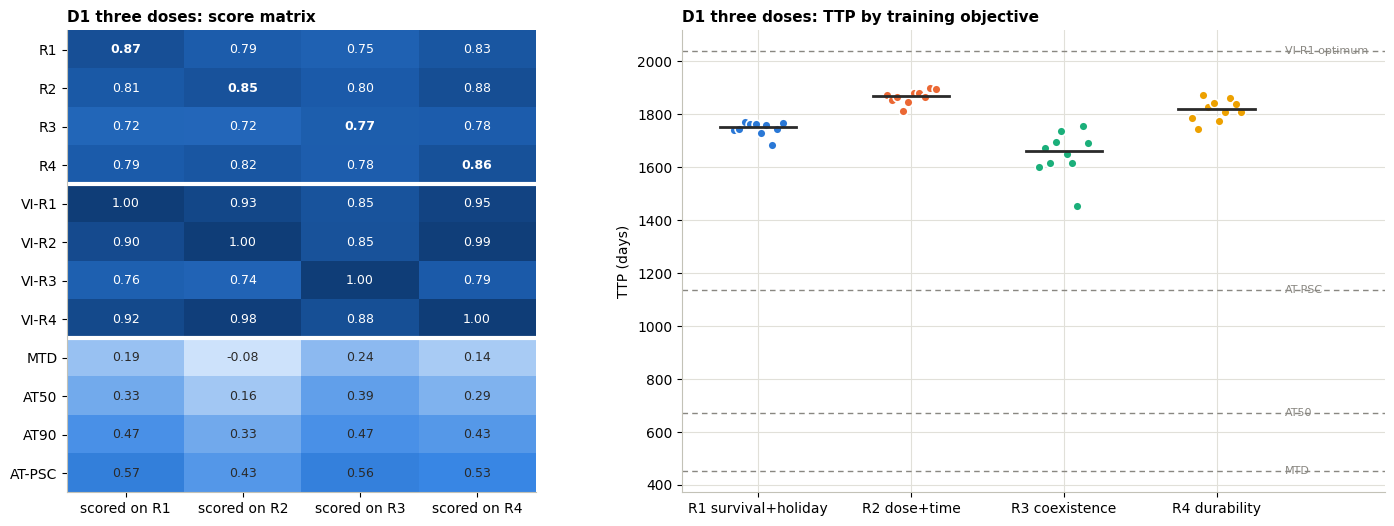

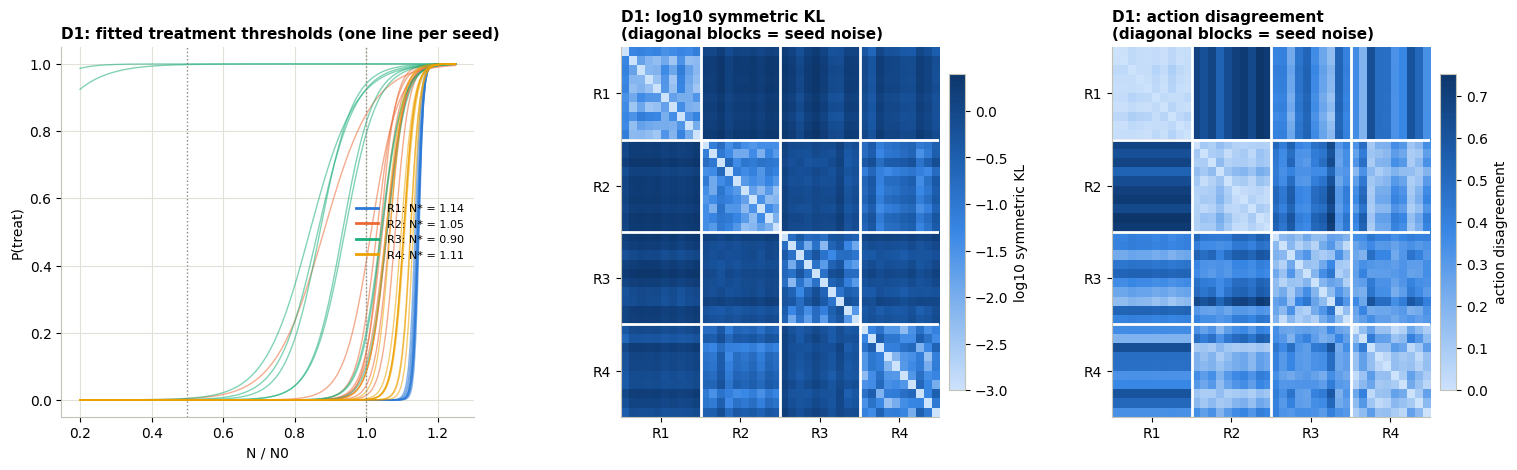

,TTP 2 doses (E3),TTP 3 doses,VI TTP 3 doses,drug 2 doses,drug 3 doses,f_holiday 2 doses,f_holiday 3 doses,own score 2 doses,own score 3 doses,trained 3 doses,half-dose share,switches/yr 2 doses,switches/yr 3 doses
R1,1743.872,1752.006,2038.0,1256.289,1259.954,0.465,0.468,0.867,0.872,10.0,0.000,27.678,27.709
R2,1726.106,1868.727,2100.0,1238.437,1341.977,0.420,0.441,0.848,0.851,10.0,0.547,28.265,33.830
R3,1493.520,1661.324,1695.0,1098.020,1213.324,0.547,0.558,0.763,0.773,10.0,0.538,27.142,30.414
R4,1750.770,1819.170,2143.0,1260.770,1308.170,0.458,0.474,0.868,0.858,10.0,0.536,27.831,33.726


,R1,R2,R3,R4
R1,0.000,0.064,0.019,0.030
R2,0.064,0.000,-0.022,-0.023
R3,0.149,0.132,0.000,0.077
R4,0.080,0.030,-0.004,0.000


,between_KL,within_KL,ratio,p_KL,between_disagree,within_disagree,p_disagree,verdict
pair,,,,,,,,
R1 vs R2,1.701,0.037,45.738,5.999e-04,0.670,0.060,5.999e-04,DIFFERENT policies
R1 vs R3,1.427,0.128,11.131,5.999e-04,0.370,0.115,5.999e-04,DIFFERENT policies
R1 vs R4,0.953,0.054,17.645,5.999e-04,0.430,0.099,5.999e-04,DIFFERENT policies
R2 vs R3,0.847,0.141,6.014,5.999e-04,0.438,0.146,5.999e-04,DIFFERENT policies
R2 vs R4,0.210,0.067,3.145,7.998e-04,0.255,0.130,7.998e-04,DIFFERENT policies
R3 vs R4,0.719,0.158,4.561,5.999e-04,0.330,0.185,5.999e-04,DIFFERENT policies


In [13]:
# Stages 3-4: categorical PPO, the central comparison against the matching 3-dose ceilings
CD1 = cross('D1', load('D1'), X3, POP, acts=DOSES3)
plot_cross(CD1, X3, 'D1 three doses'); save('D1_cross_evaluation')
plot_divergence(CD1.ps, 'D1'); save('D1_policy_divergence')
sw1 = split(switch_stats({k: CD1.ag[k] for k in CD1.ok.policy}).reset_index())
sw0 = split(switch_stats({k: C3.ag[k] for k in C3.ok.policy}).reset_index())
dB, dT = digest(C3), digest(CD1)
d1 = pd.DataFrame({o: {'TTP 2 doses (E3)': dB['TTP'][o], 'TTP 3 doses': dT['TTP'][o], 'VI TTP 3 doses': round(X3.e2.loc[f'VI-{o}', 'TTP']),
                       'drug 2 doses': dB['dose'][o], 'drug 3 doses': dT['dose'][o],
                       'f_holiday 2 doses': dB['f_holiday'][o], 'f_holiday 3 doses': dT['f_holiday'][o],
                       'own score 2 doses': dB['own_score'][o], 'own score 3 doses': dT['own_score'][o], 'trained 3 doses': dT['trained'][o],
                       'half-dose share': sw1[sw1.obj == o].share_mid.median(),
                       'switches/yr 2 doses': sw0[sw0.obj == o].per_year.median(), 'switches/yr 3 doses': sw1[sw1.obj == o].per_year.median()}
                   for o in OBJECTIVES}).T
SUMMARY['D1'] = dT | dict(half_dose_share={o: round(float(sw1[sw1.obj == o].share_mid.median()), 3) for o in OBJECTIVES},
                          switches_per_year={o: round(float(sw1[sw1.obj == o].per_year.median()), 1) for o in OBJECTIVES})
display(d1.round(3)); display(CD1.loss.round(3))
CD1.ps['div']

**Reading D1, stages 3–4.**
- **All 40 agents train**, and they learn the half dose exactly where VI uses it: on ≈ 54% of decisions for R2/R3/R4, and never for R1.
- **TTP rises** for R2 (1726 → 1869 d, +143), R3 (1494 → 1661, +168) and R4 (1751 → 1819, +68). R1 is unchanged (1752).
- **All six pairs are now DIFFERENT, including R1 vs R4** (disagreement 4.4× seed noise; R4-trained agents lose 0.080 on R1's score, R1-trained agents 0.030 on R4's). This mirrors VI and has the same cause, R1's holiday credit.
- **Coexistence gets closer but stays last.** The R1–R3 gap shrinks from 250 to 91 d, and R3's largest cost elsewhere from 0.176 to 0.149. Instrumental convergence still fails (p = 0.999).
- **The three hypotheses.**
  - **H1** (low dose improves containment): yes for R2/R3/R4, at the optimum and for agents.
  - **H2** (new differences): yes, but the main one (R1 vs R4) comes from how the reward is defined.
  - **H3** (coexistence easier): partly. R3 gains the most TTP but is still last.

### D2: action granularity, 2 vs 3 vs 5 levels [ENV]

Binary {0, 1}, three-level {0, 0.5, 1} and five-level {0, 0.25, 0.5, 0.75, 1}, with the ODE, maximum dose and decision interval unchanged. These sets are nested, so their VI ceilings must be **monotone non-decreasing**. {0, 2/3, 1} (the dose that exactly halts sensitive growth) is solved with VI only, as a non-nested variant.

Two effects pull in opposite directions: a finer action set gives the planner more flexibility but makes the choice harder for PPO. **More levels are not assumed to be better.**

D2: did not train (< 0.7 of own ceiling): ['R3|s1', 'R3|s7']
Kruskal-Wallis on TTP across objectives: H = 14.91, p = 0.0019
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


shared state set: 10151 states, N/N0 in [0.19, 1.20]


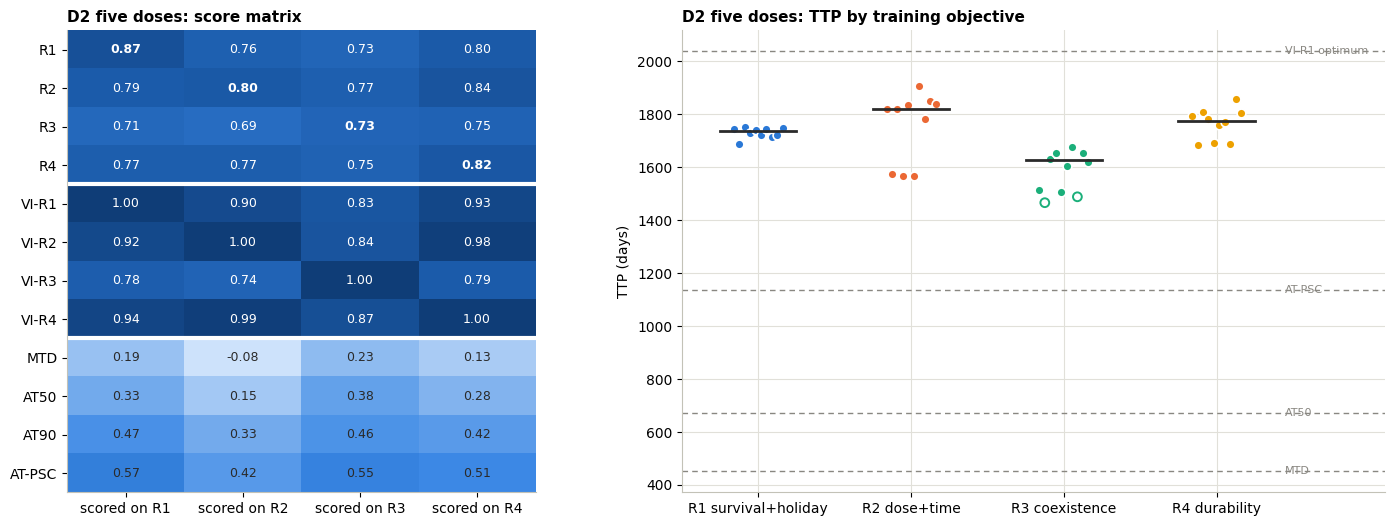

levels,2 levels,"3 levels {0, .5, 1}","3 levels {0, 2/3, 1}",5 levels
obj,,,,
R1,2038.0,2038.0,2038.0,2038.0
R2,2030.0,2100.0,2142.0,2135.0
R3,1625.0,1695.0,1724.0,1737.0
R4,2038.0,2143.0,2185.0,2205.0


levels,2 levels,"3 levels {0, .5, 1}","3 levels {0, 2/3, 1}",5 levels
obj,,,,
R1,0.0,0.000,0.010,0.014
R2,0.0,0.555,0.824,0.912
R3,0.0,0.428,0.648,0.719
R4,0.0,0.534,0.796,0.864


,2 levels (E3),3 levels (D1),5 levels (D2)
VI TTP R1/R2/R3/R4,2038/2030/1625/2038,2038/2100/1695/2143,2038/2135/1737/2205
PPO TTP R1,1743.872,1752.006,1735.335
PPO TTP R2,1726.106,1868.727,1819.627
PPO TTP R3,1493.52,1661.324,1626.441
PPO TTP R4,1750.77,1819.17,1775.619
own score R1,0.867,0.872,0.865
own score R2,0.848,0.851,0.804
own score R3,0.763,0.773,0.728
own score R4,0.868,0.858,0.816
R3 trained,10,10,8


In [14]:
X5 = ref(POP, acts=DOSES5)
X23 = {o: solve_vi(o, POP, actions=(0.0, 2 / 3, 1.0)) for o in OBJECTIVES}
LEV = {'2 levels': (P0.vi, (0.0, 1.0)), '3 levels {0, .5, 1}': (X3.vi, DOSES3), '3 levels {0, 2/3, 1}': (X23, (0.0, 2 / 3, 1.0)), '5 levels': (X5.vi, DOSES5)}
rows = []
for name, (vis, acts) in LEV.items():
    for o in OBJECTIVES:
        m = rollout(Lookahead(vis[o]), [POP], record=True); D = m['traj']['D'][:, 0]
        rows.append(dict(levels=name, obj=o, TTP=m['TTP'][0], G=m[f'G_{o}'][0], dose=m['dose'][0],
                         share_intermediate=float(np.mean((D > 0) & (D < 1))), switches_per_year=(np.diff(D) != 0).sum() / (m['TTP'][0] / 365)))
d2vi = pd.DataFrame(rows)
Gp = d2vi.pivot(index='obj', columns='levels', values='G')
assert (((Gp['3 levels {0, .5, 1}'] - Gp['2 levels']) / span > -.005) & ((Gp['5 levels'] - Gp['3 levels {0, .5, 1}']) / span > -.005)).all(), \
    'nested action sets must give monotone non-decreasing ceilings (up to grid error)'

CD2 = cross('D2', load('D2'), X5, POP, acts=DOSES5)
plot_cross(CD2, X5, 'D2 five doses'); save('D2_cross_evaluation')
sw2 = split(switch_stats({k: CD2.ag[k] for k in CD2.ok.policy}).reset_index())
dF = digest(CD2)
nd = lambda d: sum(v == 'DIFFERENT policies' for v in d['verdicts'].values())
d2 = pd.DataFrame({
    '2 levels (E3)': {'VI TTP R1/R2/R3/R4': '/'.join(f"{P0.e2.loc[f'VI-{o}', 'TTP']:.0f}" for o in OBJECTIVES),
                      **{f'PPO TTP {o}': dB['TTP'][o] for o in OBJECTIVES}, **{f'own score {o}': dB['own_score'][o] for o in OBJECTIVES},
                      'R3 trained': dB['trained']['R3'], 'drug R1': dB['dose']['R1'], 'switches/yr R1': sw0[sw0.obj == 'R1'].per_year.median(),
                      'R1-R3 gap (d)': dB['R1_R3_gap'], 'max wrong cost': dB['max_wrong_cost'],
                      'pairs DIFFERENT': sum(v['verdict'] == 'DIFFERENT policies' for v in ORIG_SUMMARY['E5_divergence'].values()),
                      'R1 vs R4': ORIG_SUMMARY['E5_divergence']['R1 vs R4']['verdict']},
    **{name: {'VI TTP R1/R2/R3/R4': '/'.join(f"{X.e2.loc[f'VI-{o}', 'TTP']:.0f}" for o in OBJECTIVES),
              **{f'PPO TTP {o}': d['TTP'][o] for o in OBJECTIVES}, **{f'own score {o}': d['own_score'][o] for o in OBJECTIVES},
              'R3 trained': d['trained']['R3'], 'drug R1': d['dose']['R1'], 'switches/yr R1': s_[s_.obj == 'R1'].per_year.median(),
              'R1-R3 gap (d)': d['R1_R3_gap'], 'max wrong cost': d['max_wrong_cost'], 'pairs DIFFERENT': nd(d), 'R1 vs R4': d['verdicts']['R1 vs R4']}
       for name, X, d, s_ in (('3 levels (D1)', X3, dT, sw1), ('5 levels (D2)', X5, dF, sw2))}})
SUMMARY['D2_VI'] = {f'{r.levels} | {r.obj}': dict(TTP=round(float(r.TTP), 1), G=round(float(r.G), 3), share_intermediate=round(r.share_intermediate, 3))
                    for r in d2vi.itertuples()}
SUMMARY['D2'] = dF
display(d2vi.pivot(index='obj', columns='levels', values='TTP').round(0))
display(d2vi.pivot(index='obj', columns='levels', values='share_intermediate').round(3))
d2

**Reading D2.**
- **The planner gains (VI, monotone as asserted).**
  - R4: 2038 → 2143 → 2205 d for 2 / 3 / 5 levels; R2: 2030 → 2100 → 2135; R3: 1625 → 1695 → 1737.
  - R1 stays at 2038 d and almost never uses an intermediate dose (1.4% at 5 levels).
  - With 5 levels, R2 and R4 spend 86–91% of weeks at an intermediate dose.
- **One well-chosen dose gets most of it.** {0, 2/3, 1}, with 2/3 the dose that exactly halts sensitive growth, reaches R2 2142 d (more than 5 levels' 2135) and R4 2185 d (5 levels: 2205).
- **The learner loses.**
  - From 3 to 5 levels, every own score falls: R2 0.851 → 0.804, R4 0.858 → 0.816, R3 0.773 → 0.728 (2 R3 seeds did not train).
  - TTP falls too (R2 1869 → 1820 d, R4 1819 → 1776 d), though it stays above binary.
  - At this budget, 3 levels is PPO's best trade-off.
- **The objective structure is unchanged** from D1: 6 pairs differ, and R3 is last (gap 109 d, largest wrong-objective cost 0.155).

**For the paper.** Whether more dose options help depends on who uses them. A single intermediate dose near the growth-halting level captures most of the planner's gain. A PPO run on {0, 2/3, 1} is the obvious next check (not done).

### D3: non-linear dose-response [ENV, VI-only]

Any benefit of intermediate dosing in D1/D2 could depend entirely on how the equations map dose to effect. The linear effect D is replaced by **D^h**, which keeps the effect at D = 0 and D = 1 fixed (a fair comparison):
- h = 0.5 is saturating (most of the effect at low dose: D = 0.5 acts like 0.71);
- h = 2 is a threshold-like curve (low doses do little: D = 0.5 acts like 0.25).

With binary doses the curve shape is irrelevant (D^h = D for D ∈ {0, 1}), which the cell checks. These are sensitivity analyses, not calibrated models (decisions F13).

In [15]:
rows = []
for h in (0.5, 1.0, 2.0):
    p = POP if h == 1.0 else patient(h=h)
    for name, acts in (('2 doses', (0.0, 1.0)), ('3 doses', DOSES3)):
        for o in OBJECTIVES:
            m = rollout(Lookahead(solve_vi(o, p, actions=acts)), [p], record=True, objs=(o,))
            rows.append(dict(h=h, actions=name, obj=o, TTP=m['TTP'][0], G=m[f'G_{o}'][0], share_half=float(np.mean(m['traj']['D'][:, 0] == .5))))
d3 = pd.DataFrame(rows)
assert d3[d3.actions == '2 doses'].groupby('obj').G.agg(lambda s: s.max() - s.min()).max() < 1e-9, 'binary doses must not depend on h'
d3t = d3.pivot_table(index=['h', 'actions'], columns='obj', values=['TTP', 'share_half'])
SUMMARY['D3'] = {f'h={h} | {a} | {o}': dict(TTP=round(float(t), 1), share_half=round(float(s), 3))
                 for h, a, o, t, s in d3[['h', 'actions', 'obj', 'TTP', 'share_half']].itertuples(index=False)}
d3t.round(3)

TTP                               share_half                     
obj                R1        R2        R3        R4         R1     R2     R3     R4
h   actions                                                                        
0.5 2 doses  2037.671  2030.281  1625.036  2037.671      0.000  0.000  0.000  0.000
    3 doses  2038.342  2058.202  1709.323  2150.073      0.014  0.841  0.637  0.737
1.0 2 doses  2037.671  2030.281  1625.036  2037.671      0.000  0.000  0.000  0.000
    3 doses  2037.671  2100.136  1695.425  2142.852      0.000  0.555  0.428  0.534
2.0 2 doses  2037.671  2030.281  1625.036  2037.671      0.000  0.000  0.000  0.000
    3 doses  2037.671  1995.039  1659.930  2093.927      0.000  0.003  0.231  0.200

**Reading D3.**
- **Binary policies are identical for every h** (asserted).
- **With three doses, the half dose's value follows the curve.**
  - **Saturating (h = 0.5**; a half dose acts like 0.71): it is used more (R2 84%, R4 74% of weeks), and R4 reaches 2150 d.
  - **Threshold-like (h = 2**; a half dose acts like 0.25): R2 nearly stops using it (0.3%), R3/R4 use it on 20–23% of weeks, and R4's gain over binary shrinks from +105 d to +56 d (2094 d).
  - R1 almost never uses it under any curve (≤ 1.4% of weeks).

**For the paper.** The graded-dose gain for R4 is qualitatively robust (positive under all three curves), but its size depends on the dose–response, which is an uncalibrated assumption. Graded-dose results should be stated as conditional on that curve.

### D4: penalise frequent dose changes [REWARD + state, VI-only]

r′_t = r_t − λ·1[D_t ≠ D_{t−1}]. The previous dose must then be part of the state, so the VI grid is replicated once per previous dose (`fx.solve_vi_switch`); the first decision is free. λ = 0 must reproduce the plain VI ceiling exactly (checked). Per-step rewards are ≈ 0.1, so λ = 0.05 makes a switch cost half a week of survival reward.

**Question.** Can a schedule be simplified a lot while keeping nearly all of its effectiveness? "Retained" is the policy's normalised score on its **un-penalised** objective. VI only: a PPO version would also need the previous dose in the agent's observation (decisions F14).

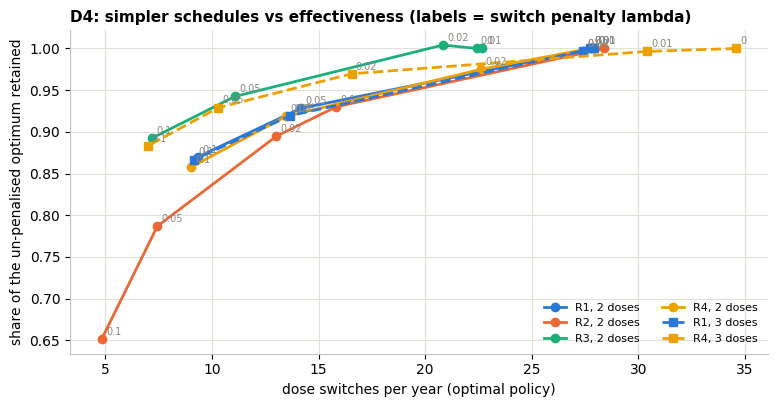

TTP                                         per_year                                retained                            
lam              0.00      0.01      0.02      0.05      0.10     0.00    0.01    0.02    0.05   0.10     0.00   0.01   0.02   0.05   0.10
actions obj                                                                                                                               
2 doses R1   2037.671  2040.251  2035.911  1879.687  1755.368   27.944  27.729  27.430  14.175  9.357      1.0  1.000  0.997  0.928  0.870
        R2   2030.281  1797.026  1681.476  1471.654  1209.133   28.405  15.843  13.024   7.441  4.830      1.0  0.930  0.895  0.787  0.652
        R3   1625.036  1628.241  1611.378  1515.714  1421.294   22.686  22.417  20.839  11.077  7.191      1.0  1.000  1.004  0.942  0.892
        R4   2037.671  2040.251  1983.334  1868.582  1740.633   27.944  27.729  22.636  13.478  9.017      1.0  1.000  0.975  0.919  0.858
3 doses R1   2037.671  2040.251  2035.911  1868.774  1750.464   27.944  27.729  27.430  13.672  9.175      1.0  1.000  0.997  0.919  0.867
        R4   2142.852  2137.355  2072.395  1983.518  1881.284   34.578  30.397  16.556  10.305  6.985      1.0  0.996  0.970  0.929  0.883

In [16]:
LAMS = (0.0, 0.01, 0.02, 0.05, 0.1)
rows = []
for acts, objs, ceil in (((0.0, 1.0), OBJECTIVES, P0.ceil), (DOSES3, ('R1', 'R4'), X3.ceil)):
    for o in objs:
        for lam in LAMS:
            m = rollout(SwitchLookahead(solve_vi_switch(o, POP, lam, acts)), [POP], record=True)
            D = m['traj']['D'][:, 0]; n = int((np.diff(D) != 0).sum())
            rows.append(dict(actions=f'{len(acts)} doses', obj=o, lam=lam, TTP=m['TTP'][0], switches=n,
                             per_year=n / (m['TTP'][0] / 365), retained=score(m[f'G_{o}'][0], o, P0.floor, ceil)))
d4 = pd.DataFrame(rows)
assert np.allclose(d4[d4.lam == 0].retained, 1, atol=1e-6), 'lambda = 0 must reproduce the plain VI optimum'
SUMMARY['D4'] = {f'{r.actions} | {r.obj} | lam={r.lam}': dict(TTP=round(r.TTP, 1), switches_per_year=round(r.per_year, 2), retained=round(r.retained, 4))
                 for r in d4.itertuples()}
fig, ax = plt.subplots(figsize=(9, 4.2))
for (a, o), d in d4.groupby(['actions', 'obj']):
    ax.plot(d.per_year, d.retained, marker='o' if a == '2 doses' else 's', ls='-' if a == '2 doses' else '--', color=COL[o], label=f'{o}, {a}')
    for r in d.itertuples():
        ax.annotate(f'{r.lam:g}', (r.per_year, r.retained), fontsize=7, color=MUTED, xytext=(3, 3), textcoords='offset points')
ax.set(xlabel='dose switches per year (optimal policy)', ylabel='share of the un-penalised optimum retained',
       title='D4: simpler schedules vs effectiveness (labels = switch penalty lambda)')
ax.legend(fontsize=8, ncol=2)
save('D4_switching_penalty')
d4.pivot_table(index=['actions', 'obj'], columns='lam', values=['per_year', 'retained', 'TTP']).round(3)

**Reading D4.** λ = 0 reproduces the plain optimum (asserted).
- **Two doses, R1/R4:** halving switching (λ = 0.05, ≈ 14 a year instead of 28) keeps 0.93/0.92 of the optimum. λ = 0.1 (≈ 9 a year) keeps 0.87/0.86.
- **Three doses are cheaper to simplify:** VI-R4 drops from 35 to 17 switches a year and keeps 0.97 (λ = 0.02).
- **R2 is the most sensitive** (0.93 at λ = 0.01, 0.65 at λ = 0.1): its optimum is close to indifferent between dosing and not, so a switching cost tips it toward treating less.
- **R3 is unaffected up to λ = 0.02.** Values a hair above 1 are grid error.
- **Even the most simplified schedule beats the heuristics by far.** At λ = 0.1 (9 switches a year), VI-R1 reaches 1755 d, 55% more than AT-PSC (1135 d with 6 switches a year).

**For the paper.** The weekly chattering is not essential. Switching every 4–6 weeks keeps ≈ 87–93% of the benefit, and that simpler schedule still far outlasts every heuristic, so a clinically legible policy class exists.

## 6. Changing the biology: E1 conversion, E2 partially sensitive resistance

### E1: sensitive → resistant conversion [ENV]

dS/dt gains −μ·S and dR/dt gains +μ·S: cells are transferred, not created, and the state stays two-dimensional. **Question:** does containment remain optimal when keeping a large sensitive population also keeps feeding new resistant cells? This is the README's named mechanism that could make durability (R4) genuinely conflict with survival (R1).

**Watch-out (doc).** With μ > 0 the resistant fraction *rises* untreated, so the self-check behind R4's design (root D14: "f never rises without drug") no longer holds. R4's per-step reward stays well-defined: it is still the fraction after a simulated 180-day holiday, which now includes conversion.

**Choosing μ (decisions F15).** A VI sweep over μ ∈ {0, 10⁻⁵, 3·10⁻⁵, 10⁻⁴, 3·10⁻⁴, 10⁻³} per day comes first. PPO is trained at the **smallest μ at which VI-R4's on-trajectory dose departs from VI-R1's by ≥ 0.5 percentage points**, so there is something for the agents to find: μ = 3·10⁻⁵.

In [17]:
Sx, Rx = np.array([0.6]), np.array([0.006])
print(f'f before a 180-day holiday {Rx[0] / (Sx[0] + Rx[0]):.4f} -> after: PoP {fraction_after_holiday(Sx, Rx, POP)[0]:.4f}, '
      f'mu = {MU:g}: {fraction_after_holiday(Sx, Rx, CONVP)[0]:.4f}  (rises with conversion)')
rows = []
for mu in (0.0, 1e-5, 3e-5, 1e-4, 3e-4, 1e-3):
    p = POP if mu == 0 else patient(mu=mu)
    ms = {o: rollout(Lookahead(solve_vi(o, p)), [p]) for o in OBJECTIVES}
    rows.append(dict(mu=mu, MTD=rollout(Const(1), [p], objs=())['TTP'][0], **{f'TTP {o}': ms[o]['TTP'][0] for o in OBJECTIVES},
                     **{f'dose% {o}': ms[o]['dose_pct'][0] for o in ('R1', 'R4')}, **{f'f_holiday {o}': ms[o]['f_holiday'][0] for o in ('R1', 'R4')},
                     R3_TTP_penalty=1 - ms['R3']['TTP'][0] / ms['R1']['TTP'][0]))
e1s = pd.DataFrame(rows).set_index('mu')
e1s['R4 - R1 dose (pp)'] = e1s['dose% R4'] - e1s['dose% R1']
SUMMARY['E1_VI_sweep'] = {str(k): r.round(4).to_dict() for k, r in e1s.iterrows()}
e1s.round(4)

f before a 180-day holiday 0.0099 -> after: PoP 0.0099, mu = 3e-05: 0.0152  (rises with conversion)


,MTD,TTP R1,TTP R2,TTP R3,TTP R4,dose% R1,dose% R4,f_holiday R1,f_holiday R4,R3_TTP_penalty,R4 - R1 dose (pp)
mu,,,,,,,,,,,
0.000e+00,451.605,2037.671,2030.281,1625.036,2037.671,71.798,71.798,0.469,0.469,0.203,0.000
1.000e-05,433.827,1541.079,1533.267,1422.096,1541.079,73.131,73.131,0.465,0.465,0.077,0.000
3.000e-05,412.916,1246.165,1211.143,1205.677,1240.107,74.709,73.945,0.490,0.444,0.033,-0.764
1.000e-04,378.769,897.057,861.206,889.530,896.352,76.472,75.751,0.495,0.457,0.008,-0.721
3.000e-04,340.234,602.428,574.649,602.428,596.334,79.014,77.473,0.533,0.489,0.000,-1.540
1.000e-03,287.140,345.195,322.445,350.008,343.216,81.114,79.542,0.617,0.584,-0.014,-1.572


E1: did not train (< 0.7 of own ceiling): none
Kruskal-Wallis on TTP across objectives: H = 24.12, p = 2.4e-05
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


shared state set: 5733 states, N/N0 in [0.27, 1.20]


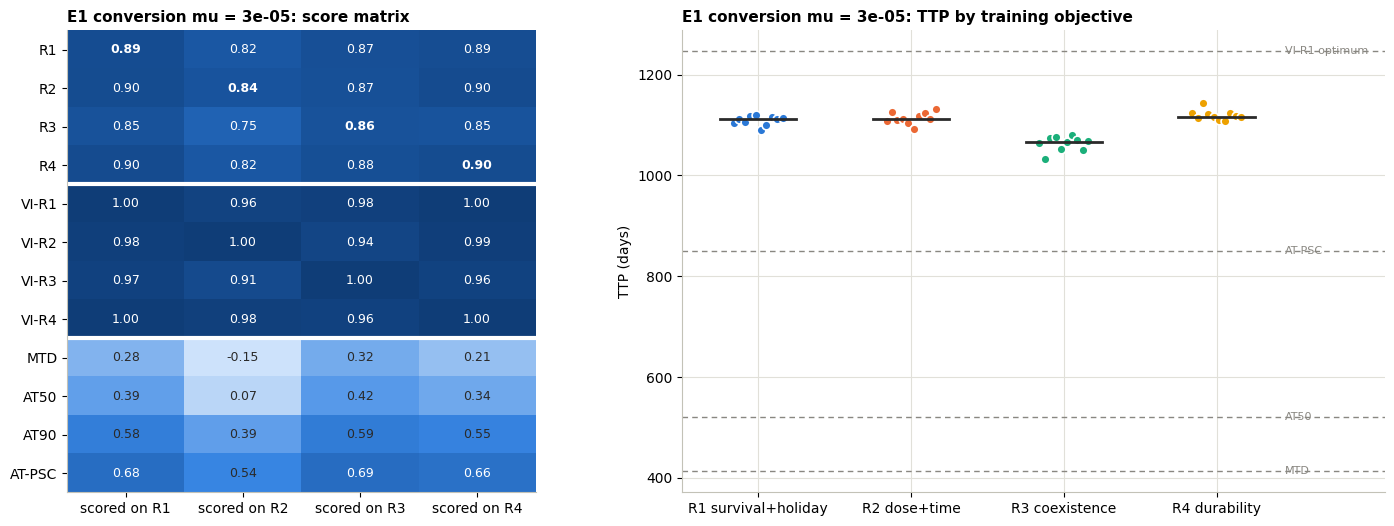

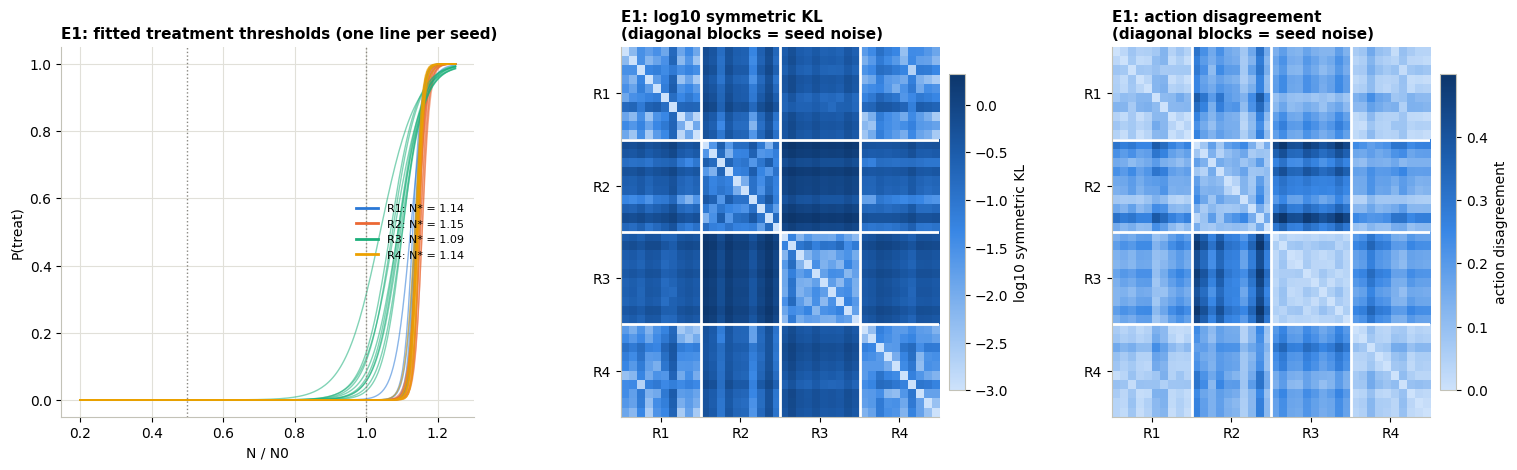

R1- vs R4-trained agents, Mann-Whitney p: {'TTP': 0.0376, 'f_holiday': 0.6776, 'dose': 0.0539}


,VI TTP,VI f_holiday,agent TTP,agent drug,agent f_holiday,own score,trained
R1,1246.0,0.490,1112.181,829.549,0.487,0.893,10.0
R2,1211.0,0.388,1112.099,819.907,0.436,0.842,10.0
R3,1206.0,0.503,1066.850,807.850,0.549,0.857,10.0
R4,1240.0,0.444,1116.314,835.648,0.489,0.896,10.0


,R1,R2,R3,R4
R1,0.000,0.023,-0.013,0.007
R2,-0.005,0.000,-0.010,-0.003
R3,0.038,0.092,0.000,0.050
R4,-0.006,0.023,-0.019,0.000


,between_KL,within_KL,ratio,p_KL,between_disagree,within_disagree,p_disagree,verdict
pair,,,,,,,,
R1 vs R2,0.344,0.083,4.151,5.999e-04,0.182,0.097,5.999e-04,DIFFERENT policies
R1 vs R3,0.361,0.046,7.864,5.999e-04,0.168,0.060,5.999e-04,DIFFERENT policies
R1 vs R4,0.058,0.049,1.191,6.239e-02,0.071,0.069,1.820e-01,not distinguishable from seed noise
R2 vs R3,1.132,0.070,16.270,5.999e-04,0.323,0.085,5.999e-04,DIFFERENT policies
R2 vs R4,0.273,0.073,3.748,5.999e-04,0.166,0.094,5.999e-04,DIFFERENT policies
R3 vs R4,0.484,0.036,13.549,5.999e-04,0.206,0.056,5.999e-04,DIFFERENT policies


In [18]:
XC = ref(CONVP)
CE1 = cross('E1', load('E1'), XC, CONVP)
plot_cross(CE1, XC, f'E1 conversion mu = {MU:g}'); save('E1_cross_evaluation')
plot_divergence(CE1.ps, 'E1'); save('E1_policy_divergence')
dE = digest(CE1)
e1t = pd.DataFrame({o: {'VI TTP': round(XC.e2.loc[f'VI-{o}', 'TTP']), 'VI f_holiday': round(XC.e2.loc[f'VI-{o}', 'f_holiday'], 3),
                        'agent TTP': dE['TTP'][o], 'agent drug': dE['dose'][o], 'agent f_holiday': dE['f_holiday'][o],
                        'own score': dE['own_score'][o], 'trained': dE['trained'][o]} for o in OBJECTIVES}).T
r14 = {m: stats.mannwhitneyu(CE1.ok[CE1.ok.obj == 'R1'][m], CE1.ok[CE1.ok.obj == 'R4'][m]).pvalue for m in ('TTP', 'f_holiday', 'dose')}
print('R1- vs R4-trained agents, Mann-Whitney p:', {k: round(float(v), 4) for k, v in r14.items()})
SUMMARY['E1'] = dE | dict(VI_TTP={o: round(float(XC.e2.loc[f'VI-{o}', 'TTP'])) for o in OBJECTIVES}, R1_vs_R4_mannwhitney_p=r14)
display(e1t); display(CE1.loss.round(3))
CE1.ps['div']

**Reading E1.**
- **Conversion shortens everything.** At μ = 3·10⁻⁵, VI-R1 reaches 1246 d (no conversion: 2038 d) and MTD 413 d. The resistant fraction after a 180-day holiday now rises (0.0099 → 0.0152 in the check above).
- **At the optimum, durability departs from survival, but only slightly.** VI-R4 ends with a lower resistant fraction after a 180-day holiday (0.444 vs 0.490), at 0.8 points lower dose intensity and 6 d less TTP (1240 vs 1246). The dose difference grows with μ (≈ −1.5 points at μ ≥ 3·10⁻⁴) but stays small.
- **R3's survival penalty shrinks with μ** (20% → 3% at μ = 3·10⁻⁵, ≈ 0 from 3·10⁻⁴). When conversion makes resistant cells anyway, aiming for coexistence costs little extra.
- **For the agents (all 40 train), R1 and R4 remain indistinguishable:**
  - policy space: disagreement 1.04× seed noise, p = 0.18;
  - post-holiday fraction: 0.487 vs 0.489, p = 0.68;
  - drug: p = 0.054;
  - TTP: differs by 4 d (p = 0.038, not significant at the Bonferroni α = 0.0083).

  The R4 agents do not capture VI-R4's durability gain (0.489 vs 0.444). Costs among R1/R2/R4 stay ≤ 0.023, and R3's largest cost falls to 0.092.

**For the paper.** Conversion is the first setting where the *optimum* separates durability from survival, as the README predicted. The split is small and invisible to agents at this budget. R1 ≡ R4 is robust for learners, approximate for the planner.

### E2: partially drug-sensitive resistant cells [ENV, VI-only]

The resistant growth term gets a multiplier (1 − ε·d̂_D·D); ε = 0 recovers the original model. **Question:** does coexistence (R3) underperform because the objective is problematic, or because the resistant population cannot be controlled directly in this model? If R3 improves as ε grows, the original result depends on the assumption of complete resistance.

**A correction to the proposal (decisions F16).** The doc says ε > 0 "is what lets the drug reverse" resistant growth. On PoP (turnover 0) that is not so for any ε < 2/3: R's per-capita rate under full dose is r_R(1 − N/K)(1 − 1.5ε) − d_T, which stays positive. Partial sensitivity *slows* R but cannot shrink it unless there is turnover. The sweep is therefore run on PoP **and** on the A1 turnover-0.04 patient, where ε ≳ 0.4 lets a full dose shrink R near the progression line. The last column of the table reports that rate.

In [19]:
rows = []
for pname, bp in (('PoP', POP), ('turnover 0.04', TURNP)):
    for e in (0.0, 0.1, 0.2, 0.3, 0.4, 0.5):
        p = bp if e == 0 else {**bp, 'eps': e}
        ms = {o: rollout(Lookahead(solve_vi(o, p)), [p], record=True) for o in OBJECTIVES}
        capped = any(m['TTP'][0] >= CFG['tmax'] for m in ms.values())
        tr3 = ms['R3']['traj']
        rows.append(dict(patient=pname, eps=e, capped=capped, **{f'TTP {o}': ms[o]['TTP'][0] for o in OBJECTIVES},
                         R3_TTP_penalty=1 - ms['R3']['TTP'][0] / ms['R1']['TTP'][0], R3_band_time=float(np.mean(entropy(tr3['S'][:, 0], tr3['R'][:, 0]) >= 0.9995 * H2MAX)),
                         R3_mean_fR=ms['R3']['mean_fR'][0], R1_eq_R4=bool(abs(ms['R1']['TTP'][0] - ms['R4']['TTP'][0]) < 1),
                         R_rate_full_dose_at_line=p['rR'] * (1 - CFG['prog'] * p['N0'] / p['K']) * (1 - e * p['dD']) - p['dT']))
e2s = pd.DataFrame(rows).set_index(['patient', 'eps'])
SUMMARY['E2'] = {f'{a} | eps={b}': r.to_dict() for (a, b), r in e2s.round(4).iterrows()}
e2s.round(4)

capped     TTP R1     TTP R2     TTP R3     TTP R4  R3_TTP_penalty  R3_band_time  R3_mean_fR  R1_eq_R4  R_rate_full_dose_at_line
patient       eps                                                                                                                                  
PoP           0.0   False   2037.671   2030.281   1625.036   2037.671           0.203         0.004       0.092      True                 2.700e-03
              0.1   False   2310.293   2289.365   1841.388   2310.293           0.203         0.015       0.102      True                 2.300e-03
              0.2   False   2667.961   2653.378   2135.887   2667.961           0.199         0.013       0.113      True                 1.900e-03
              0.3   False   3150.606   3108.261   2534.124   3150.117           0.196         0.011       0.128      True                 1.500e-03
              0.4   False   3836.141   3766.244   3101.175   3822.638           0.192         0.011       0.152     False                 1.100e-03
              0.5   False   4886.167   4830.377   3983.417   4879.205           0.185         0.016       0.186     False                 7.000e-04
turnover 0.04 0.0   False   3388.765   3388.765   2681.544   3388.765           0.209         0.013       0.131      True                 1.600e-03
              0.1   False   3892.238   3885.631   3066.628   3892.238           0.212         0.011       0.149      True                 1.200e-03
              0.2   False   4571.456   4564.444   3626.671   4571.456           0.207         0.012       0.175      True                 8.000e-04
              0.3   False   5558.142   5565.133   4494.174   5565.133           0.191         0.014       0.217     False                 4.000e-04
              0.4    True  10950.000  10950.000  10950.000  10950.000           0.000         0.006       0.617      True                 0.000e+00
              0.5    True  10950.000  10950.000  10950.000  10950.000           0.000         0.008       0.539      True                -4.000e-04

**Reading E2.**
- **PoP.** Partial sensitivity lengthens every optimum strongly (VI-R1 2038 → 4886 d at ε = 0.5). R3's survival penalty barely moves (20.3% → 18.5%), and VI-R3 is inside its band on ≤ 1.6% of weeks. R1 ≡ R4 holds to ε = 0.3, then splits by < 0.4% of TTP.
- **Turnover 0.04.** Up to ε = 0.3 the picture is the same (penalty 19–21%).
  - At ε ≥ 0.4, a full dose shrinks resistance at the progression line (the rate column reaches ≤ 0), and **every optimum hits the 30-year cap**.
  - The patient no longer progresses, so the control problem and its ceilings disappear; R3 does not improve. A 0 penalty there is the cap, not a result.
  - Even then, VI-R3 is in its band on < 1% of weeks.

**For the paper.** R3 is not last because resistance is complete. Wherever the patient progresses, coexistence costs ≈ 20% of survival at every ε. This defends finding F-d.

## 7. B4: sensitivity to the progression threshold [ENV-lite, VI-only]

The episode ends at N ≥ 1.2 N₀, a convention rather than a biological law. Here the threshold is moved to 1.1 N₀ and 1.3 N₀ and VI is re-solved for every objective. The VI burden grid spans [0.02, threshold]·N₀, so it extends automatically. With n₀ = 0.75, 1.3 N₀ = 0.975 K, which is close to carrying capacity, so we go no higher. The E0 reproduction numbers (CT 451.6 d, AT50 662.8 d) apply only at 1.2.

**VI-only (decisions F17).** A PPO version needs `CFG['prog']` inside the spawned workers (a module-level constant). The question is whether *the optimum's* objective ranking moves, which VI answers directly.

In [20]:
rows, saved = [], CFG['prog']
try:
    for th in (1.1, 1.2, 1.3):
        CFG['prog'] = th                     # read by advance() and Grid(): this kernel only
        vis = {o: solve_vi(o, POP) for o in OBJECTIVES}
        ms = {o: rollout(Lookahead(v), [POP]) for o, v in vis.items()}
        rows.append(dict(threshold=th, MTD=rollout(Const(1), [POP], objs=())['TTP'][0], AT50=rollout(ATx(.5), [POP], objs=())['TTP'][0],
                         **{f'TTP {o}': ms[o]['TTP'][0] for o in OBJECTIVES}, R1_R4_same_policy=bool((vis['R1']['pol'] == vis['R4']['pol']).all()),
                         R3_TTP_penalty=1 - ms['R3']['TTP'][0] / ms['R1']['TTP'][0],
                         ranking=' > '.join(sorted(OBJECTIVES, key=lambda o: -ms[o]['TTP'][0]))))
finally:
    CFG['prog'] = saved
b4 = pd.DataFrame(rows).set_index('threshold')
SUMMARY['B4'] = {str(k): {c: (v if isinstance(v, (str, bool)) else round(float(v), 4)) for c, v in r.items()} for k, r in b4.iterrows()}
b4.round(3)

,MTD,AT50,TTP R1,TTP R2,TTP R3,TTP R4,R1_R4_same_policy,R3_TTP_penalty,ranking
threshold,,,,,,,,,
1.1,426.690,633.264,1176.022,1141.433,1015.231,1176.022,False,0.137,R1 > R4 > R2 > R3
1.2,451.605,673.219,2037.671,2030.281,1625.036,2037.671,False,0.203,R1 > R4 > R2 > R3
1.3,507.820,755.696,7812.014,7791.036,5740.522,7812.014,False,0.265,R1 > R4 > R2 > R3


**Reading B4.**
- **The 1.2 row reproduces E1/E2** (MTD 451.6 d, AT50 673.2 d at weekly decisions; VI 2038/2030/1625/2038 d).
- **The ranking R1 = R4 > R2 > R3 holds at every threshold.** R1 and R4 give identical TTP everywhere (their grid policies differ only off-trajectory).
- **The threshold scales everything.** VI-R1 reaches 1176 / 2038 / 7812 d at 1.1 / 1.2 / 1.3 N₀. At 1.3 N₀ (0.975 K) the tumour sits near its carrying capacity, so regrowth to the line is very slow.
- **R3's penalty grows with the threshold:** 13.7% → 20.3% → 26.5%.

**For the paper.** The progression convention sets the size of every TTP and of R3's penalty, but not the conclusions.

## 8. Not done here, and why

| Item | Why not | What it would take |
|---|---|---|
| **A4** daily agents at 7× budget (equal simulated days) | Cadence is not part of the headline story; the doc says "worth doing only if cadence is part of the headline". It is the most expensive item (≈ 140M steps). | 20 jobs with `interval=1, steps=7_000_000` in `fx.fjobs`. |
| **A5** E6–E10 on the cost-0.42 patient | Low priority by the doc: E3c showed the E3–E5 conclusions carry over. | Re-run E6–E10 cells with `COSTP`. |
| **E3** noisy / delayed burden readings | Needs new observation plumbing in `VecEnv`/`Agent` (noise and a lagged chart) and 40+ runs per variant. It is the **most relevant next step** for findings 7–8 ("observation matters more than objective"). | An `obs='burden_noisy'` mode built on E11b; see `relevance.md`. |
| **E4** agent chooses when to measure next | Changes the time structure of the MDP; the doc calls it the most invasive and optional. | Variable Δ per step with γ_Δ = 0.999^(Δ/7) (already used in E9). |
| PPO versions of D3, D4, E2, B4 | VI already answers each question at the optimum. PPO is worth adding only where VI shows an effect worth explaining. | Jobs in `fx.fjobs`; D4 also needs the previous dose in the observation. |
| **Part F**: R5 toxicity, spatial structure, PK, immune cells, plasticity, an LSTM, another RL algorithm, clinical claims | Out of scope by the doc itself: state them as limitations. | — |

## 9. Findings, and what they mean for the paper

All numbers are from this run (`results/summary.json`). Each item names its section.

### Robustness: reviewer attacks that no longer hold
| Attack | Answer | § |
|---|---|---|
| "The VI ceilings are coarse" | doubling the grid moves no ceiling by > 0.4% | A3 |
| "One parameter set" | R1 ≡ R4 and R3 last over the whole cost × turnover box (25 VI patients) and for PPO on a third patient (turnover 0.04) | C1, A1 |
| "Your agents trained badly" | at 3× budget scores reach 0.93–0.97; divergence *grows* (R1 vs R3 3.8× → 6.1× seed noise); R3's cost stays 0.15 with full state | A2 |
| "It is your R3 reward maths" | smooth entropy is worse; smooth targets cannot be held, by VI either: the limit is structural | B2 |
| "It assumes fully resistant cells" | R3's survival penalty stays ≈ 20% at every ε while the patient still progresses | E2 |
| "Progression at 1.2 N₀ is arbitrary" | ranking R1 = R4 > R2 > R3 at 1.1, 1.2 and 1.3 | B4 |

### New insights
1. **What the policy sees bounds what the objective can do** (A2). At equal 3M budgets, burden + critic beats full state for every objective (p ≤ 4·10⁻⁴), and memory is weakest. With a burden-only actor the objectives nearly collapse (R3's largest cost 0.023 vs 0.154 with full state), because the actor cannot see what R3 rewards.
2. **R2 is Pareto-efficient, not broken** (B1). All good policies sit on one drug–TTP line at ≈ 72% intensity. The R2 memory agents trade ≈ 285 d of TTP for ≈ 4 points of intensity and form the intensity and resistance frontiers.
3. **R1 ≡ R4 is a statement about how a holiday is credited** (D1). Add a half dose, and an all-or-nothing holiday bonus splits survival (2038 d) from durability (2143 d). A dose-proportional bonus (`R1p`) gives *exactly* the R4 optimum again. Under S → R conversion (E1) the planner shows the first genuine split, but it is small (6 d, 4.6 points of post-holiday resistance) and invisible to agents.
4. **Intermediate doses help the planner more than the learner** (D1–D3). Three doses add 70–105 d at the optimum and 68–168 d for agents (R2/R3/R4). Five levels add more for VI but *lower* PPO's scores. A single growth-halting dose (2/3) captures most of the gain. The size depends on the dose–response curve.
5. **Optimal schedules chatter, and can be simplified** (B3, D4). Optima and agents switch dose on ≈ 54% of weeks (heuristics ≤ 22%). A switching penalty halves switching for 3–8% of the benefit, and the 9-switches-a-year VI schedule still outlasts the best heuristic by 55%.
6. **Coexistence's cost scales with its target** (B2). A target near the containment fraction (f\* = 0.05) costs almost nothing (0.029). Every higher target costs more, and no policy holds f above ≈ 0.12. Survival-trained agents beat coexistence-trained agents on every coexistence reward.

### Where each piece goes
- **Main text:** A2 (equal budgets, insight 1); B1 frontier (insight 2); D1 with `R1p` (insight 3); E1 as the qualified durability result; B2 as the strongest defence of "R3 last".
- **Supplement:** A3, A1, C1 map, D2–D4, E2, B4.
- **Next steps:**
  1. E3, noisy or delayed burden readings: directly extends insight 1.
  2. PPO with doses {0, 2/3, 1}.
  3. PPO for D4, with the previous dose in the observation.

In [21]:
with open(f'{RES}/summary.json', 'w') as f:
    json.dump(SUMMARY, f, indent=1, default=float)
print('results/summary.json written:', ', '.join(SUMMARY))

results/summary.json written: B1, B1_frontier, B2, A3, A1, A2, A2_equal_budget_TTP, C1, B3, D1_VI, D1, D2_VI, D2, D3, D4, E1_VI_sweep, E1, E2, B4
